# ANFIS-FCM sMoE U-Net — Explainable Edge Detection
### v9 — honest uncertainty (CIs, classic-grid columns, cap-at-optimum), 8-fold TTA, ensemble tooling (no model/training change)

**What the v8 run showed.** ODS barely moved when the grid was extended (0.7489 -> 0.7481; `best_t` was 0.01 both times), so ODS was *not* truncated; OIS (0.751 -> 0.762) and AP (0.675 -> 0.791) rose because their per-image / tail parts need thresholds below 0.01. The AP advantage over the paper therefore comes with the extended grid and the dense high-recall tail (the prediction cap binds for many images); with the classic 0.01-0.99 grid (v7) AP was below the paper's. The remaining ODS gap (MS-TTA 0.7591 vs paper 0.7628) is ~0.004.

**v9 changes**
1. **Uncertainty + transparency in every row:** 95% CI by bootstrapping test images (ODS/OIS/AP), paired bootstrap ANFIS-vs-backbone, "classic grid" ODS/OIS/AP printed beside the extended-grid ones, and the number of images where the prediction cap binds *at the ODS-optimal threshold*.
2. **8-fold dihedral TTA** (`'ms8'`: scales x 4 flips x 2 transposes), all views in-distribution. Inference-only.
3. **Ensemble tooling:** `SAVE_TEST_PREDS` stores each row's test probability maps; `RUN_TAG`/`SEED` train an independent second member; the last cell scores the averaged ensemble with CIs. Must be reported as an N-model ensemble.
4. `EVAL_ROWS` selects which (head, mode) rows to evaluate (default: both heads, MS-TTA).

Nothing here tunes the NMS, the grid or the cap towards a target; those stay fixed as in v8.

**Added after v9 review (ODS lever):** `EVAL_MAXNORM` also scores every row after per-image max-normalisation (`p / max(p)`, label-free, no parameter). The ODS-vs-OIS gap (~0.014) shows the best threshold differs per image; this aligns score scales across images. It is a **post-processing variant** reported on separate `-maxnorm` rows: disclose it, and do not compare a `-maxnorm` row with un-normalised numbers (paper or otherwise). It can also lower ODS - check the CI.

---
### (v8 notes follow)
### v8 — evaluation grid brackets the optimum + Phase-0a backbone diagnostic (v7 head and v6 protocol kept)

**Why v8.** In the v7 run `best_t` was **0.010 - the lowest point of the threshold grid - in all six rows**, and max recall stopped at 0.75-0.77. ODS/AP depend only on how the detector *ranks* pixels, so a grid that does not contain the optimal operating point under-estimates ODS and, much more, AP(full) (which is zero-filled beyond the recall actually reached). These detectors are under-confident (soft-label BCE + Dice on ~5% positive pixels), so their useful operating range sits below 0.01.

**v8 changes (measurement + diagnostics only; no model / training change)**
1. **Threshold grid.** `standard` protocol = 99 linear points in [0.01, 0.99] **plus 8 log-spaced points in [1e-4, 0.01)** (fixed a priori, no per-image normalisation, no test-set tuning). A boundary check now warns if the optimum is still at a grid edge. On a synthetic test, a map scaled x0.01 scored ODS 0.000 on the old grid and 0.844 on the new one (unscaled: 0.847) - i.e. the metric is again invariant to output scale, as ODS should be.
2. **Cap.** `MAX_PRED_STANDARD = 30000` (was 15000) and a note is printed if it still binds at the lowest threshold. Identical capped sets are matched once (output-identical, saves time).
3. **TTA.** Flip-only TTA off by default (+<=0.0015 ODS in v7); multi-scale scales now (0.75, 1, 1.25, 1.5), inside the training scale range 0.7-1.5.
4. **Last cell:** scores the *pre-Stage-B* backbone (`phase0a_warmup_v6.pt`) to show whether joint Stage-B training helped or hurt the backbone (v6 -> v7 the post-Stage-B backbone moved 0.7505/0.7588/0.7055 -> 0.7485/0.7525/0.6838 although Phase 0a is identical).

**Numbers from older versions are NOT comparable to v8 numbers** (different grid); compare rows within one v8 run.

---
### (v7 notes follow)
### v7 — logit-consequent TSK head (identity init) + multi-scale TTA row (backbone, v6 evaluation protocol kept)

**Why v7.** In the v6 run (standard protocol) the ANFIS head scored *below* the backbone it wraps: ODS 0.7381 vs 0.7505, OIS 0.7299 vs 0.7588, AP 0.6208 vs 0.7055, max recall 0.703 vs 0.793. Cause: the TSK consequents were linear in the *probability* `x2` and the sum then went through a sigmoid. A probability moves only 0-1, so the head's pre-sigmoid value spans roughly `q`, while the backbone's logit spans ~15 units. The head therefore (i) puts a floor under every background pixel (~sigmoid(r_background)), and (ii) squeezes weak-but-real edges onto the same output level as background, so the low-confidence / high-recall part of the PR curve is lost.

**v7 changes**
1. **Logit-consequent TSK head.** Antecedents are unchanged (Gaussian MFs on `x1`, `x2`; FCM geometry; firing maps). Only the second consequent *input* changes from `x2` to its log-odds `z2 = unet_logits`: `y_i = p_i*x1 + q_i*z2 + r_i`, `P = sigmoid(sum_i wbar_i*y_i)`. Consequents start at the identity (`p=0, q=1, r=0`), so **the head equals the backbone at initialisation** and training can only move away from it where the Sobel/rule structure helps. The LSE initialisation is bypassed in this mode (set `HEAD_LOGIT_CONSEQUENTS=False` to restore the v6 head). **This is a departure from the base paper's consequent definition and must be disclosed.**
2. **Multi-scale + flip TTA** row (scales 0.75/1/1.25 x 4 flips), reported separately and labelled. Inference-only.
3. Phase 0a backbone checkpoint (`phase0a_warmup_v6.pt`) is **reused** (no backbone retraining); Phase 0b / training-state checkpoints are versioned `*_v7.pt`. Candidate-R* fine-tune LR lowered 5e-3 -> 5e-4 so scoring stays near the identity start. Sobel calibration is off by default (already run).

---
### (v6 notes follow)
### v6 — protocol-aligned evaluation + deep supervision + longer backbone training (v5 fixes kept)

**v6 changes (on top of v5):**
1. **Evaluation (largest change).** v4/v5 scored *unthinned* maps against the *union* of annotators with a single 1:1 match. v6 adds a `'standard'` protocol (edge NMS thinning; each annotator matched separately; recall pooled over annotators; precision = predicted px matched to >=1 annotator; tolerance 0.0075 x diagonal) and keeps the old one as `'legacy'`. Both are reported side by side; a Sobel calibration check compares both protocols against the base paper's own Sobel row. **This changes the yardstick, not the model - report both.** It is also ~4-5x faster (thin maps = far fewer pixels to match).
2. **Deep supervision (architecture, train-time only).** Three 1x1 side-output heads on decoder levels d4/d3/d2, supervised with the same BCE+Dice and annealed to zero weight over the first 80% of Phase 0a. They are discarded at inference/Stage B; the forward path, sMoE blocks, U-Net, Sobel and ANFIS head are untouched.
3. **Phase 0a 65 -> 150 epochs**, retrained from scratch (so the v5 rotation fix finally applies to the backbone; the v5 run reused the old backbone checkpoint).
4. **Flip test-time augmentation** (4 flips) as a separately labelled evaluation row.

Checkpoints are versioned `*_v6.pt`; v5 checkpoints are left on disk and can be re-scored under the new protocol in the last cell.

---
### (v5 notes follow)
### v5 — ANFIS-head initialization fix + 2 supporting fixes (architecture, loss, LSE solver, eval protocol unchanged)

**v5 changes (found by auditing the v4 run's logs/curves):**
1. **Root cause of the ANFIS-side degradation.** `init_consequents_lse()` fits the TSK consequents to the *probability* target, but the head then applies `sigmoid()` to that sum. A linear fit to `y in [0,1]` therefore yields pre-sigmoid values near 0 for background, i.e. **P = 0.5 on every background pixel at initialization** (BCE ~0.69). That is why Stage A started at val loss ~0.58 versus the backbone's own ~0.45, and why Stage B then crawled down ~linearly for all 350 epochs and was still improving when it hit `MAX_EPOCHS` (best epoch = last epoch). Fix: the *same, unmodified* `init_consequents_lse()` is now called with the **logit** of the (clipped) target. The function body is byte-for-byte identical to v4.
2. **Stage-B BatchNorm bug.** While the decoder was "frozen" (Stage-B epochs 1..`DECODER_UNFREEZE_EPOCH`), its BN layers were still in train mode, so running statistics kept drifting and `x2` (the feature the FCM rules were fitted on) shifted anyway. Frozen decoder -> BN eval, same as Stage A.
3. **Augmentation bug.** `TF.rotate(img, 90/270)` with `expand=False` on non-square BSDS images clips content and adds ~33% black bars (with no GT), which also creates fake Sobel edges. Replaced by lossless `transpose` rotations.

Checkpoints `phase0b` / `training_state` are renamed `*_v5.pt` so stale v4 files (built on the broken initialization) are **not** resumed. `phase0a_warmup.pt` is unchanged and still reused (see the config note).

---
### (v4 notes follow)
### v4 — Diagnostics, native XAI, and two real bugs fixed (architecture unchanged)

Builds on v3 (root-cause convergence fixes). This version adds numerical
stability and diagnostic/XAI features recommended in a follow-up review,
**without touching** the U-Net encoder/decoder, the 3 sMoE blocks, Sobel
preprocessing, or the LSE consequent-initialization already in place.

**Two real bugs found by actually running v3 on Kaggle are fixed here too:**
1. Phase 0b called `model(imgs)` directly on **full-resolution validation
   images**, which aren't guaranteed divisible by 16 -- causes an encoder/
   decoder skip-connection shape mismatch. Now uses the shared
   `pad_to_multiple` / `predict_native` utilities (moved earlier in the
   notebook so Phase 0b can use them instead of duplicating them).
2. The per-candidate sigma computation `um[k] * (X - ck[None,:])**2` doesn't
   broadcast (`(N,)` against `(N,2)`) and throws a `ValueError` in real
   execution -- fixed with explicit `um[k].reshape(-1,1)`.

**Explicitly NOT changed, per your instruction:** `init_consequents_lse()` is
untouched -- no ridge-LSE changes, same closed-form solve as v3.

| Review item | Added? |
|---|---|
| Rule-collapse diagnostics (mean/max firing, dominance %) | ✅ |
| Stable σ: `softplus(ρ)+ε` reparameterization + log-domain Gaussian | ✅ |
| Ridge-LSE change | ❌ explicitly excluded per your instruction |
| Feature-drift monitoring (x2 before vs after backbone unfreeze) | ✅ |
| Backbone-vs-ANFIS direct comparison (P_backbone vs P_ANFIS on ODS/OIS/AP) | ✅ |
| Rule contribution maps (`w̄ᵢ × TSKᵢ`, distinct from firing maps) | ✅ |
| Entropy/uncertainty map | ✅ |
| Rule semantic profiling table | ✅ |
| FCM seed stability (Adjusted Rand Index across 5 seeds) | ✅ |
| Calibration (ECE/Brier), λ ablation, multi-seed final eval | Not added — flagged as optional follow-ups to keep this response scoped |
| Model checkpoint saving / Kaggle auto-save | **Removed** — best weights are kept in memory only (`copy.deepcopy` of `state_dict`), nothing is written to disk |


In [1]:
import torch, sys
print('Python:', sys.version)
print('Torch :', torch.__version__)
print('CUDA  :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU   :', torch.cuda.get_device_name(0))
    print(f'VRAM  : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Torch : 2.11.0+cu128
CUDA  : True
GPU   : Tesla T4
VRAM  : 15.6 GB
Device: cuda


In [2]:
!pip install -q numpy matplotlib opencv-python-headless scipy Pillow tqdm scikit-learn
print('Dependencies installed')


Dependencies installed


## Cell — Imports & Configuration

In [3]:
import os, warnings, random, math, time, copy, hashlib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import cv2
from tqdm import tqdm
import scipy.io
from PIL import Image
from scipy.stats import wasserstein_distance
from sklearn.metrics import adjusted_rand_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
import torchvision.transforms as T
from sklearn.metrics import auc

warnings.filterwarnings('ignore')

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

BATCH_SIZE    = 4
LAMBDA_DICE   = 0.5
BASE_CH       = 64

CROP_SIZE             = 320
TILE_SIZE             = CROP_SIZE
TILE_STRIDE           = CROP_SIZE // 2
PAD_MULTIPLE          = 16
EDGE_CROP_PROB        = 0.50   # [TUNED] was 0.30. Edge pixels are a small minority of
                                # BSDS500; biasing more crops toward them directly
                                # targets the class-imbalance side of slow convergence
                                # on top of the LR fix.
SCALE_RANGE           = (0.6, 1.8)
EVAL_FULL_IMAGE_FIRST = True

# No checkpoint directory needed anymore -- best weights are kept in memory
# only. WORK_DIR is used solely for saved figures (plots), not model state.
WORK_DIR  = '/kaggle/working/smoe_results_v4'
BSR_ROOT  = '/kaggle/working/BSR/BSDS500'
os.makedirs(WORK_DIR, exist_ok=True)

# --- §6.2 FCM Clustering & Rule Count Determination -------------------------
FCM_CANDIDATE_R     = [4, 6, 8, 10, 12]
FCM_SEEDS           = 5
FCM_SAMPLE_PIXELS   = 1_000_000
FCM_MAX_ITER        = 60
FCM_M               = 2.0

FCM_SAMPLING_MODE   = 'balanced'   # 'natural' | 'balanced' | 'ratio_25_75'
FCM_EDGE_FRACTION   = 0.30
FCM_EDGE_GT_THRESH  = 0.3

XB_SHORTLIST_MARGIN  = 0.15   # unused for gating now (kept for reference); see XB_SHORTLIST_TOP_K
XB_SHORTLIST_TOP_K   = 3      # Item 5: shortlist = top-K candidates by rank
R_STAR_PARSIMONY_TOL = 0.003
PROXY_ODS_THRESHOLDS = 21
PROXY_TOL_PIX        = 2

FCM_CANDIDATE_TRAIN_EPOCHS = 8
FCM_CANDIDATE_LR            = 5e-4   # [v7: was 5e-3] head starts at identity (== backbone); keep R* scoring close to it

BACKBONE_WARMUP_EPOCHS = 150  # [v6: was 65] [older note: was 40; Phase 0a's logged final loss (0.4569)
                              # was still above the paper's reported ~0.35 -- the
                              # backbone hadn't finished converging in 40 epochs.
                              # Paired with a cosine LR decay (Phase 0a cell) so the
                              # extra epochs actually help rather than plateauing flat.

# [FIXED] Phase 0a was previously optimized with LR_DECODER (1e-5) below --
# a Stage-B FINE-TUNING rate, ~10-100x too small to train a randomly
# initialized 39M-parameter backbone from scratch in 25 epochs. This is
# the primary cause of the reported ODS/OIS/AP shortfall vs. the paper.
# LR_WARMUP matches the base paper's stated Adam lr=1e-4 (Section 3.1).
LR_WARMUP = 1e-4

# Sigma is now sigma = softplus(rho) + SIGMA_INIT_EPS -- always positive,
# differentiable, and never silently clamped/clipped (replaces v3's adaptive
# floor/ceiling clamp entirely -- review item 'stable sigma parameterization').
SIGMA_INIT_EPS = 1e-3

# Sigma ceiling (new, isolated addition -- see ANFISFuzzyHead.update_sigma_ceiling).
# Caps each rule's effective sigma at factor * (distance to its nearest
# neighboring rule center), so no rule's membership function can grow wide
# enough to overlap a neighboring rule's territory. Does not touch the
# consequents, the LSE init, the loss, R* selection, or evaluation protocol.
SIGMA_CEILING_FACTOR = 0.5
SIGMA_CEILING_MIN    = 0.02

ALPHA_BACKBONE          = 0.3
FROZEN_BASELINE_EPOCHS  = 15
MAX_EPOCHS  = 350   # [TUNED] was 250. Last run hit this ceiling with best_val_loss
                    # still improving at epoch 264 -- early stopping (patience=25)
                    # never triggered, meaning training was cut off, not converged.
PATIENCE    = 25

LR_ANFIS            = 1e-4
LR_DECODER          = 2e-5   # [TUNED] was 1e-5. This rate is appropriate for gently
                             # fine-tuning an already-good decoder -- but this backbone
                             # (0.46 warm-up loss vs. paper's ~0.35) still needs real
                             # improvement, not just protection. Modest 2x bump, still
                             # far below LR_ANFIS (1e-4) so drift risk stays low.
LR_ENCODER          = 2e-6   # [TUNED] was 1e-6, same reasoning as LR_DECODER.
MF_LR_MULTIPLIER    = 2
MF_FREEZE_EPOCHS       = 5
ENCODER_UNFREEZE_EPOCH = 20   # [TUNED] was 40. Backbone was frozen for the first 40
                              # of 250 Stage-B epochs (~16% of the budget spent idle);
                              # unfreezing earlier gives it more effective steps within
                              # the same overall epoch budget.
# FIX: decoder_params includes unet_head, which directly produces x2. It was
# previously unfrozen from Stage-B epoch 1 (LR_DECODER=1e-5), well before the
# encoder -- meaning x2 could drift from the FCM-fitted geometry long before
# ENCODER_UNFREEZE_EPOCH ever mattered. Now protected on the same schedule.
DECODER_UNFREEZE_EPOCH = 20   # [TUNED] was 40, same reasoning as ENCODER_UNFREEZE_EPOCH.

# [DRIFT-ANCHOR, added] The delayed-unfreeze above only slows x2 drift down;
# it doesn't stop it once unet_head unfreezes at DECODER_UNFREEZE_EPOCH. Two
# further protections, both purely additive (no architecture/LSE/loss-shape
# change to anything else):
#   1. unet_head gets its OWN optimizer param group at a much smaller LR than
#      the rest of the decoder, instead of sharing LR_DECODER.
#   2. An anchor loss L_drift gently pulls x2's mean/std back toward the
#      Phase-0b snapshot (x2_dist_before) whenever unet_head is unfrozen.
LR_X2_HEAD    = 1e-6    # 10x smaller than LR_DECODER -- x2 is what the FCM
                        # rules were fitted on, so it gets the most protection
                        # of anything that is allowed to move at all.
LAMBDA_DRIFT  = 0.02    # [TUNED] was 0.05. Loosened so the now-slightly-higher
                        # LR_DECODER/LR_ENCODER above aren't fighting an anchor term
                        # that was tuned for the previous, more conservative LRs.

# [ADDED] Weight on the new rule-utilization (entropy) regularizer -- targets
# observed rule collapse (one rule ~91% dominant, another ~0%) directly,
# which the sigma-ceiling geometric safeguard alone did not prevent.
LAMBDA_RULE_UTIL = 0.02
DRIFT_REPORT_EVERY_N_EPOCHS = 10   # print live drift-loss alongside train/val loss

GRAD_CLIP_NORM = 3.0

# --- v5 ----------------------------------------------------------------------
# Targets for the one-time closed-form LSE are clipped to [eps, 1-eps] and mapped
# through logit(), because the head output is sigmoid(sum_i w_i * TSK_i). Without
# this the TSK sum is fitted as if it were a probability (sigmoid(0)=0.5 floor).
LSE_LOGIT_EPS = 0.02

# Checkpoint names. Phase 0b and the training state were produced with the v4
# (probability-space) LSE init, so they are versioned and will NOT be resumed.
# Phase 0a (backbone only) is unaffected by the head fix and is still reused.
# NOTE: the backbone in that checkpoint was trained with the old rotation
# augmentation (black bars). To retrain it cleanly, change CKPT_PHASE0A to
# 'phase0a_warmup_v5.pt'.
RUN_TAG = ''   # [v9] ensemble-member tag. For a 2nd member: set SEED=1 (top of this cell) AND RUN_TAG='_s1' -> trains a fresh backbone
CKPT_PHASE0A = f'phase0a_warmup_v6{RUN_TAG}.pt'   # [v6] fresh backbone: deep supervision + rotation fix
CKPT_PHASE0B = f'phase0b_rstar_v7{RUN_TAG}.pt'    # [v7] head definition changed -> do NOT resume v6 Phase 0b / training state
CKPT_TRAIN   = f'training_state_v7{RUN_TAG}.pt'   # (CKPT_PHASE0A stays v6: the backbone is unchanged and is reused)

# --- v6 ------------------------------------------------------------------------
# Deep supervision (train-time side outputs on decoder levels d4/d3/d2).
USE_DEEP_SUPERVISION = True
AUX_WEIGHT           = 0.2    # per side head, relative to the main loss (weight 1.0)
AUX_ANNEAL_FRAC      = 0.8    # aux weight falls linearly to 0 over the first 80% of Phase 0a

# Evaluation. 'standard' = thinned maps + per-annotator matching + diagonal tolerance;
# 'legacy' = the v4/v5 protocol (kept for like-for-like comparison with earlier logs).
EVAL_N_THRESH          = 99
EVAL_TTA               = False    # (superseded by EVAL_ROWS in v9) # [v8: was True] flip-only TTA gained <=0.0015 ODS in v7; MS-TTA subsumes it (saves ~1.2 h)
EVAL_LEGACY_ALSO       = False    # set True ONCE for a legacy-protocol row (slow: ~1-2 h per model)
NMS_SIGMA              = 2.0      # smoothing for the NMS orientation estimate
RUN_SOBEL_CALIBRATION  = False    # score raw Sobel under both protocols vs the paper's Sobel row
SOBEL_CALIB_N_IMAGES   = 50       # subset size for that check (full set: 200)
#   (v6 result, 50-image subset: Sobel ODS standard=0.4837, legacy=0.4688; paper Sobel row = 0.5769)

# --- v7 ------------------------------------------------------------------------
# TSK consequents use the LOG-ODDS of x2 (= unet_logits) instead of the probability x2, and start
# at the identity (p=0, q=1, r=0) so head == backbone at initialisation. Antecedents unchanged.
HEAD_LOGIT_CONSEQUENTS = True
EVAL_MS_TTA            = True               # also report multi-scale + flip TTA rows
EVAL_MS_SCALES         = (0.75, 1.0, 1.25, 1.5)   # [v8: +1.5] inside the training scale range (0.7-1.5)

# --- v8 -------------------------------------------------------------------------
# Standard-protocol grid: 99 linear points 0.01..0.99 PLUS EVAL_N_LOW log-spaced points in [EVAL_T_LOW, 0.01).
# (v7: best_t was the lowest grid point 0.01 in every row -> the optimum was outside the grid.)
EVAL_N_LOW        = 8
EVAL_T_LOW        = 1e-4
MAX_PRED_STANDARD = 30000     # cap on thinned predicted pixels per image (legacy protocol keeps 15000)
# --- v9 -------------------------------------------------------------------------
# Rows to evaluate: (head, mode); mode in {'plain','flip','ms','ms8'}  ('ms8' = scales x 8 dihedral views).
EVAL_ROWS       = [('anfis', 'ms8'), ('backbone', 'ms8')]   # 8-fold TTA rows (the ODS lever); 'ms' rows already measured in v8
EVAL_MAXNORM    = True      # also score each row after per-image max-normalisation (label-free, parameter-free)
EVAL_BOOTSTRAP  = 1000                 # test-image bootstrap resamples for 95% CIs (0 = off)
SAVE_TEST_PREDS = True                 # save test probability maps of each evaluated row (for ensembling)
PRED_DIR        = f'{WORK_DIR}/preds'

RUN_PHASE0A_BACKBONE_EVAL = True    # score the pre-Stage-B backbone (phase0a_warmup_v6.pt) -> isolates Stage-B effect
PHASE0A_EVAL_MS           = False   # also score it with MS-TTA (adds ~1 h)

# --- New diagnostics (this version) -----------------------------------------
RULE_DIAG_EVERY_N_EPOCHS   = 20   # print rule-collapse diagnostics this often in Stage B
FEATURE_DRIFT_N_BATCHES    = 20   # val batches used to capture x2 distribution snapshots
EVALUATE_BACKBONE_BASELINE = True # also run the full ODS/OIS/AP protocol on P_backbone
                                   # (doubles evaluation time -- set False to skip)

print('Config ready (v4 -- diagnostics + 2 real bugs fixed, architecture/LSE unchanged)')
print(f'Sigma parameterization: softplus(rho) + {SIGMA_INIT_EPS} (no clamp)')
print(f'Evaluate backbone baseline too: {EVALUATE_BACKBONE_BASELINE}')
print(f'v8: eval grid +{EVAL_N_LOW} log points down to {EVAL_T_LOW:g}; cap {MAX_PRED_STANDARD}; TTA flip={EVAL_TTA} ms={EVAL_MS_TTA}')
print(f'v7: logit-consequent head={HEAD_LOGIT_CONSEQUENTS}, MS-TTA={EVAL_MS_TTA} {EVAL_MS_SCALES}')
print(f'v6: deep-supervision={USE_DEEP_SUPERVISION} (w={AUX_WEIGHT}), Phase0a epochs={BACKBONE_WARMUP_EPOCHS}')
print(f'v5: logit-space LSE targets (eps={LSE_LOGIT_EPS}); ckpts: {CKPT_PHASE0A} / {CKPT_PHASE0B} / {CKPT_TRAIN}')


Config ready (v4 -- diagnostics + 2 real bugs fixed, architecture/LSE unchanged)
Sigma parameterization: softplus(rho) + 0.001 (no clamp)
Evaluate backbone baseline too: True
v8: eval grid +8 log points down to 0.0001; cap 30000; TTA flip=False ms=True
v7: logit-consequent head=True, MS-TTA=True (0.75, 1.0, 1.25, 1.5)
v6: deep-supervision=True (w=0.2), Phase0a epochs=150
v5: logit-space LSE targets (eps=0.02); ckpts: phase0a_warmup_v6.pt / phase0b_rstar_v7.pt / training_state_v7.pt


## Cell — Checkpoint / Save-Point Utilities [ADDED]

Adds disk-backed checkpointing and auto-resume for the three expensive/stateful stages below (Phase 0a backbone warm-up, Phase 0b FCM rule discovery, and the Stage A/B training loop), so a Kaggle session restart does not require recomputing them from scratch. This does not remove or alter the existing in-memory `best_state_dict` tracking already used later in the notebook -- it is purely additive.

In [4]:
CHECKPOINT_DIR = f'{WORK_DIR}/checkpoints'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

def save_checkpoint(state: dict, filename: str):
    path = os.path.join(CHECKPOINT_DIR, filename)
    torch.save(state, path)
    print(f'[checkpoint saved] {path}')

def load_checkpoint(filename: str):
    path = os.path.join(CHECKPOINT_DIR, filename)
    if os.path.exists(path):
        print(f'[checkpoint found] loading {path}')
        return torch.load(path, map_location=DEVICE)
    return None

print(f'Checkpoint directory ready: {CHECKPOINT_DIR}')


Checkpoint directory ready: /kaggle/working/smoe_results_v4/checkpoints


## Cell — Download BSDS500 (unchanged)

In [5]:
import tarfile

BSR_TGZ = '/kaggle/working/BSR_bsds500.tgz'
BSR_DIR  = '/kaggle/working/BSR'

if not os.path.exists(os.path.join(BSR_DIR, 'BSDS500', 'data', 'images', 'train')):
    print('Downloading BSDS500...')
    os.system(f'wget -q --show-progress '
              f'https://www2.eecs.berkeley.edu/Research/Projects/CS/vision/grouping/BSR/BSR_bsds500.tgz '
              f'-O {BSR_TGZ}')
    with tarfile.open(BSR_TGZ, 'r:gz') as tar:
        tar.extractall('/kaggle/working/')
    print('Extracted.')
else:
    print('BSDS500 already present.')

for split in ['train', 'val', 'test']:
    n_img = len([f for f in os.listdir(f'{BSR_DIR}/BSDS500/data/images/{split}') if f.endswith('.jpg')])
    n_gt  = len([f for f in os.listdir(f'{BSR_DIR}/BSDS500/data/groundTruth/{split}') if f.endswith('.mat')])
    print(f'  [{split:>5}]  images={n_img}  gt_mats={n_gt}')

BSR_ROOT = f'{BSR_DIR}/BSDS500'
print('Dataset ready')


BSDS500 already present.
  [train]  images=200  gt_mats=200
  [  val]  images=100  gt_mats=100
  [ test]  images=200  gt_mats=200
Dataset ready


## Cell — Sobel Edge Detector (unchanged from v3 -- global-scale calibration)

In [6]:
class SobelEdgeDetector(nn.Module):
    def __init__(self):
        super().__init__()
        kx = torch.tensor([[-1,0,1],[-2,0,2],[-1,0,1]], dtype=torch.float32)
        ky = torch.tensor([[-1,-2,-1],[0,0,0],[1,2,1]],  dtype=torch.float32)
        self.register_buffer('kx', kx.view(1,1,3,3))
        self.register_buffer('ky', ky.view(1,1,3,3))
        self.register_buffer('global_scale', torch.tensor(1.0))
        self.calibrated = False

    def _raw_magnitude(self, x_raw):
        gray = 0.2126*x_raw[:,0:1] + 0.7152*x_raw[:,1:2] + 0.0722*x_raw[:,2:3]
        gray = F.pad(gray, (1,1,1,1), mode='reflect')
        gx   = F.conv2d(gray, self.kx, padding=0)
        gy   = F.conv2d(gray, self.ky, padding=0)
        return torch.sqrt(gx**2 + gy**2 + 1e-8)

    def forward(self, x_raw):
        mag = self._raw_magnitude(x_raw)
        if self.calibrated:
            return (mag / self.global_scale).clamp(0, 1)
        B = mag.shape[0]
        flat = mag.view(B, -1)
        mn = flat.min(1, keepdim=True)[0].view(B,1,1,1)
        mx = flat.max(1, keepdim=True)[0].view(B,1,1,1)
        return (mag - mn) / (mx - mn + 1e-8)

    @torch.no_grad()
    def calibrate(self, x_raw_batches, percentile=99.0):
        mags = []
        for x_raw in x_raw_batches:
            mags.append(self._raw_magnitude(x_raw).flatten().cpu())
        all_mag = torch.cat(mags).numpy()
        scale = float(np.percentile(all_mag, percentile))
        self.global_scale.fill_(max(scale, 1e-4))
        self.calibrated = True
        return scale

print('SobelEdgeDetector defined -- unchanged from v3')


SobelEdgeDetector defined -- unchanged from v3


## Cell — sMoE Block ([ADDED] corner/junction expert -- still exactly 3 skip-connection instances -- e2/e3/e4)

context_expert and boundary_expert (and their weights/behaviour) are byte-for-byte unchanged. A third expert, `CornerJunctionExpert` (asymmetric 1x3/3x1 + multi-scale dilation-1/dilation-3 kernels), is added, and the gate is widened from a single Sigmoid weight to a 3-channel Softmax so it can weight all three experts.

In [7]:
class CornerJunctionExpert(nn.Module):
    """[REVERTED] Back to full (non-depthwise-separable) convolutions -- the
    depthwise-separable variant measurably reduced ODS/OIS/AP for both the
    backbone and the ANFIS head (a controlled A/B on this exact notebook),
    consistent with depthwise convs trading away cross-channel mixing
    capacity that this specialist branch was relying on. Same four spatial
    branches, same semantics: horizontal (1x3), vertical (3x1), local (3x3),
    and larger-context dilated (3x3, dilation=3), concatenated and projected
    back to out_ch.
    """
    def __init__(self, in_ch, out_ch):
        super().__init__()
        mid = max(out_ch // 2, 8)
        self.horiz   = nn.Conv2d(in_ch, mid, kernel_size=(1, 3), padding=(0, 1), bias=False)
        self.vert    = nn.Conv2d(in_ch, mid, kernel_size=(3, 1), padding=(1, 0), bias=False)
        self.scale1  = nn.Conv2d(in_ch, mid, kernel_size=3, padding=1, dilation=1, bias=False)
        self.scale2  = nn.Conv2d(in_ch, mid, kernel_size=3, padding=3, dilation=3, bias=False)
        self.project = nn.Conv2d(mid * 4, out_ch, kernel_size=1, bias=False)
        self.bn  = nn.BatchNorm2d(out_ch)
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        feats = torch.cat([self.horiz(x), self.vert(x), self.scale1(x), self.scale2(x)], dim=1)
        return self.act(self.bn(self.project(feats)))


class sMoEBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.context_expert = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=2, dilation=2, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
        self.boundary_expert = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
        # [ADDED] third expert (corner/junction), alongside the original two.
        self.corner_expert = CornerJunctionExpert(in_ch, out_ch)
        # [CHANGED] gate widened from a single Sigmoid weight (2-way convex
        # combination) to a 3-channel Softmax (3-way combination) so it can
        # also weight the new corner expert. This is the only change to the
        # gate itself; context_expert and boundary_expert are byte-for-byte
        # unchanged above.
        self.gate = nn.Sequential(
            nn.Conv2d(1, 3, 1),
            nn.Softmax(dim=1),
        )

    def forward(self, x, edge_signal):
        e = F.interpolate(edge_signal, size=x.shape[-2:],
                          mode='bilinear', align_corners=False)
        g      = self.gate(e)                 # (B, 3, H, W): [context, boundary, corner] weights
        sharp  = self.boundary_expert(x)
        smooth = self.context_expert(x)
        corner = self.corner_expert(x)         # [ADDED]
        y      = g[:, 0:1] * smooth + g[:, 1:2] * sharp + g[:, 2:3] * corner
        return y, g

print('sMoEBlock defined -- 3 experts now (context / boundary / corner-junction [ADDED]); '
      'still exactly 3 skip-connection instances -- e2/e3/e4')


sMoEBlock defined -- 3 experts now (context / boundary / corner-junction [ADDED]); still exactly 3 skip-connection instances -- e2/e3/e4


## Cell — ANFIS Fuzzy Head + FCM/Xie-Beni utilities
### Numerical-stability and native-XAI additions (review items)

- **Stable σ:** `GaussianMF` now parameterizes sigma as
  `softplus(rho) + SIGMA_INIT_EPS` instead of a raw parameter clamped after
  the fact -- always positive, always differentiable, never silently clipped.
- **Log-domain Gaussian:** membership is computed as
  `exp(log_mu)` where `log_mu = -(x-c)^2 / (2 sigma^2)` is computed directly
  in log space before a single `exp`, avoiding repeated underflow-prone
  intermediate values.
- **`init_consequents_lse` is UNCHANGED from v3** -- no ridge-LSE edits, per
  your instruction.
- New helper functions for rule-collapse diagnostics, entropy maps, and
  per-rule contribution maps (all read off existing tensors -- no new
  architecture).


In [8]:
def fuzzy_c_means(X, c, m=2.0, max_iter=60, tol=1e-5, seed=0):
    rng = np.random.RandomState(seed)
    N, D = X.shape
    u = rng.rand(c, N); u /= u.sum(axis=0, keepdims=True)
    centers = None
    for _ in range(max_iter):
        um = u ** m
        centers = (um @ X) / um.sum(axis=1, keepdims=True).clip(min=1e-8)
        dist = np.linalg.norm(X[None, :, :] - centers[:, None, :], axis=2) + 1e-8
        new_u = 1.0 / (dist ** (2 / (m - 1)))
        new_u /= new_u.sum(axis=0, keepdims=True)
        if np.abs(new_u - u).max() < tol:
            u = new_u; break
        u = new_u
    return centers, u


def xie_beni_index(X, centers, u, m=2.0):
    dist2 = np.linalg.norm(X[None, :, :] - centers[:, None, :], axis=2) ** 2
    numer = (u ** m * dist2).sum()
    csep  = np.linalg.norm(centers[:, None, :] - centers[None, :, :], axis=2)
    np.fill_diagonal(csep, np.inf)
    denom = X.shape[0] * (csep.min() ** 2)
    return numer / max(denom, 1e-8)


def sample_pixels(x1_flat, x2_flat, gt_flat, n_take, mode, edge_fraction,
                   edge_thresh, rng):
    """Named, switchable sampling strategy: 'natural' | 'balanced' | 'ratio_25_75'.
    Returns (x1_sel, x2_sel, gt_sel)."""
    if mode == 'natural':
        n_take = min(n_take, len(x1_flat))
        sel = rng.choice(len(x1_flat), n_take, replace=False)
        return x1_flat[sel], x2_flat[sel], gt_flat[sel]

    frac = 0.25 if mode == 'ratio_25_75' else edge_fraction
    is_edge = gt_flat > edge_thresh
    edge_idx     = np.flatnonzero(is_edge)
    non_edge_idx = np.flatnonzero(~is_edge)

    n_edge_take = min(int(round(n_take * frac)), len(edge_idx))
    n_non_take  = min(n_take - n_edge_take, len(non_edge_idx))

    sel_edge = rng.choice(edge_idx, n_edge_take, replace=False) if n_edge_take > 0 else np.array([], dtype=int)
    sel_non  = rng.choice(non_edge_idx, n_non_take, replace=False) if n_non_take > 0 else np.array([], dtype=int)
    sel = np.concatenate([sel_edge, sel_non])
    return x1_flat[sel], x2_flat[sel], gt_flat[sel]


# ============================================================================
# ANFIS fuzzy head (5 layers, Jang 1993)
#   L1 Fuzzification    - GaussianMF, FCM-initialised, softplus-sigma, log-domain
#   L2 Rule firing       - product T-norm
#   L3 Normalisation     - w_i / sum(w)  -> Rule Firing Maps (XAI)
#   L4 Consequents       - nn.Parameter, LSE-INITIALIZED ONCE (unchanged from v3),
#                          then trained by backprop
#   L5 Output            - sum of weighted consequents -> sigmoid
# ============================================================================
def _inverse_softplus(y, eps=SIGMA_INIT_EPS):
    """Solve softplus(rho) + eps = y for rho, used only at initialization."""
    y_adj = max(y - eps, 1e-4)
    return math.log(math.expm1(y_adj)) if y_adj < 20 else y_adj


class GaussianMF(nn.Module):
    """sigma = softplus(rho) + eps: always positive, differentiable, never
    clamped (review safeguard B). Membership computed in log-domain before a
    single exp (review safeguard A)."""
    def __init__(self, init_center: float, init_sigma: float = 0.35, sigma_eps: float = SIGMA_INIT_EPS):
        super().__init__()
        _c0 = min(max(init_center, 1e-4), 1 - 1e-4)
        self.center_raw = nn.Parameter(torch.tensor(math.log(_c0 / (1 - _c0)), dtype=torch.float32))
        _rho0 = _inverse_softplus(max(init_sigma, sigma_eps * 2), sigma_eps)
        self.sigma_raw = nn.Parameter(torch.tensor(_rho0, dtype=torch.float32))
        self.sigma_eps = sigma_eps

    @property
    def center(self):
        return torch.sigmoid(self.center_raw)

    @property
    def sigma(self):
        return F.softplus(self.sigma_raw) + self.sigma_eps

    def forward(self, x, ceiling=None):
        """`ceiling`, if given, upper-bounds the EFFECTIVE sigma used this call
        (does not touch sigma_raw/the learned parameter itself -- purely a
        forward-pass cap, still fully differentiable through torch.minimum)."""
        eff_sigma = self.sigma if ceiling is None else torch.minimum(self.sigma, ceiling)
        log_mu = -((x - self.center) ** 2) / (2 * eff_sigma ** 2 + 1e-8)
        return torch.exp(log_mu)


class ANFISRule(nn.Module):
    def __init__(self, cx1, cx2, sigma=0.35):
        super().__init__()
        self.mf_x1 = GaussianMF(cx1, sigma)
        self.mf_x2 = GaussianMF(cx2, sigma)

    def forward(self, x1, x2, ceiling=None):
        return self.mf_x1(x1, ceiling) * self.mf_x2(x2, ceiling)


class ANFISFuzzyHead(nn.Module):
    def __init__(self, n_rules=4, init_centers=None, init_sigmas=None):
        super().__init__()
        self.n_rules = n_rules
        if init_centers is None:
            init_centers = [(0.8,0.8),(0.2,0.8),(0.2,0.2),(0.8,0.2)][:n_rules]
        if init_sigmas is None:
            init_sigmas = [(0.35, 0.35)] * n_rules
        self.rules = nn.ModuleList([ANFISRule(cx1, cx2) for cx1, cx2 in init_centers])
        for rule, (s1, s2) in zip(self.rules, init_sigmas):
            rule.mf_x1.sigma_raw.data.fill_(_inverse_softplus(max(s1, SIGMA_INIT_EPS*2)))
            rule.mf_x2.sigma_raw.data.fill_(_inverse_softplus(max(s2, SIGMA_INIT_EPS*2)))
        self.consequents = nn.Parameter(torch.zeros(n_rules, 3))
        # [ADDED v7] logit-consequent mode: second consequent input is z2 = logit(x2) (the backbone logit).
        # Identity init (p=0, q=1, r=0) => the head reproduces the backbone exactly before training.
        self.logit_consequents = bool(globals().get('HEAD_LOGIT_CONSEQUENTS', True))
        if self.logit_consequents:
            self.consequents.data[:, 1] = 1.0
        # Sigma ceiling: one scalar per rule, default large (effectively a
        # no-op) until update_sigma_ceiling() is called with real geometry.
        self.register_buffer('sigma_ceiling', torch.full((n_rules,), 10.0))

    @torch.no_grad()
    def update_sigma_ceiling(self, factor=None, min_ceiling=None):
        """Recompute each rule's sigma ceiling from CURRENT center positions:
        factor * (Euclidean distance to nearest other rule's center), floored
        at min_ceiling. Call after construction and periodically during
        training as centers move. Isolated addition -- reads centers only,
        writes only the sigma_ceiling buffer; does not touch consequents,
        sigma_raw, or any other parameter."""
        factor = SIGMA_CEILING_FACTOR if factor is None else factor
        min_ceiling = SIGMA_CEILING_MIN if min_ceiling is None else min_ceiling
        centers = torch.stack([
            torch.stack([r.mf_x1.center, r.mf_x2.center]) for r in self.rules
        ])  # [R, 2]
        R = centers.shape[0]
        if R < 2:
            self.sigma_ceiling.fill_(10.0)
            return
        dist = torch.cdist(centers, centers)          # [R, R]
        dist.fill_diagonal_(float('inf'))
        nearest = dist.min(dim=1).values               # [R]
        self.sigma_ceiling.copy_((factor * nearest).clamp(min=min_ceiling))

    @torch.no_grad()
    def init_consequents_lse(self, x1_flat, x2_flat, y_flat, ridge=1e-2):
        """UNCHANGED from v3 -- one-time closed-form LSE fit, never re-run during
        training. Per-parameter adaptive ridge only (no further ridge-LSE changes,
        per instruction)."""
        device = self.consequents.device
        x1 = torch.as_tensor(x1_flat, dtype=torch.float32, device=device).view(-1, 1)
        x2 = torch.as_tensor(x2_flat, dtype=torch.float32, device=device).view(-1, 1)
        y  = torch.as_tensor(y_flat,  dtype=torch.float32, device=device).view(-1, 1)

        firings = torch.stack([rule(x1, x2, self.sigma_ceiling[i]) for i, rule in enumerate(self.rules)], dim=1).squeeze(-1)
        wsum = firings.sum(dim=1, keepdim=True).clamp(min=1e-8)
        wbar = firings / wsum

        R = self.n_rules
        ones = torch.ones_like(x1)
        # [v7] in logit mode the regressor is z2=logit(x2) (antecedent firings above still use x2).
        x2_feat = torch.logit(x2.clamp(1e-6, 1 - 1e-6)) if self.logit_consequents else x2
        phi = torch.stack([wbar * x1, wbar * x2_feat, wbar * ones.expand_as(wbar)], dim=2)
        phi = phi.reshape(-1, R * 3)

        A = phi.T @ phi
        diag_scale = A.diagonal().clamp(min=1.0)
        A = A + ridge * torch.diag(diag_scale)
        b = phi.T @ y
        theta = torch.linalg.solve(A, b).reshape(R, 3)
        self.consequents.data.copy_(theta)

    def forward(self, x1, x2, z2=None):
        """Pure feed-forward, identical at train/eval time.
        z2: backbone logits (same shape as x2). Only used in logit-consequent mode; if omitted it is
        recovered as logit(x2), which equals unet_logits up to float saturation."""
        firings = torch.stack([rule(x1, x2, self.sigma_ceiling[i]) for i, rule in enumerate(self.rules)], dim=1).squeeze(2)  # [B,R,H,W]
        # [v7] logit mode: a far-out pixel must not shrink sum(wbar) below 1 (that would pull the output
        # toward sigmoid(0)=0.5). Use a much smaller floor there; the v6 probability head keeps 1e-8.
        wsum    = firings.sum(dim=1, keepdim=True).clamp(min=(1e-30 if self.logit_consequents else 1e-8))
        wbar    = firings / wsum                                                        # L3, XAI maps

        p = self.consequents[:, 0].view(1, -1, 1, 1)
        q = self.consequents[:, 1].view(1, -1, 1, 1)
        r = self.consequents[:, 2].view(1, -1, 1, 1)
        if self.logit_consequents:
            feat2 = (z2 if z2 is not None else torch.logit(x2.clamp(1e-6, 1 - 1e-6))).clamp(-20.0, 20.0)
        else:
            feat2 = x2
        rule_out = p * x1 + q * feat2 + r
        y_hat = (wbar * rule_out).sum(dim=1, keepdim=True)
        output = torch.sigmoid(y_hat).squeeze(1)
        return output, wbar


# ----------------------------------------------------------------------------
# Native diagnostics / XAI helpers -- all derived from existing tensors
# (wbar, consequents, x1, x2). No new architecture.
# ----------------------------------------------------------------------------
@torch.no_grad()
def log_rule_geometry(anfis_head, tag=''):
    """Step 2: periodic centroid-distance + sigma(vs. ceiling) logging, so the
    sigma ceiling's actual effect during training becomes observable instead
    of only inferable from the pre-training snapshot and final metrics.
    Diagnostic only -- reads existing buffers/parameters, writes nothing."""
    centers = torch.stack([torch.stack([r.mf_x1.center, r.mf_x2.center])
                            for r in anfis_head.rules]).cpu()
    raw_sigma = torch.stack([torch.stack([r.mf_x1.sigma, r.mf_x2.sigma])
                              for r in anfis_head.rules]).cpu()
    ceiling = anfis_head.sigma_ceiling.cpu()
    R = centers.shape[0]
    if R < 2:
        print(f'  [rule geometry{tag}] R=1, no pairwise distance to report')
        return
    dists = torch.cdist(centers.unsqueeze(0), centers.unsqueeze(0)).squeeze(0)
    dists.fill_diagonal_(float('inf'))
    flat_idx = int(dists.argmin())
    i, j = flat_idx // R, flat_idx % R
    n_binding = int((raw_sigma.max(dim=1).values > ceiling).sum())
    print(f'  [rule geometry{tag}] min pairwise center dist={dists[i,j]:.3f} (R{i+1}-R{j+1})  '
          f'raw sigma: min={raw_sigma.min():.3f} mean={raw_sigma.mean():.3f} max={raw_sigma.max():.3f}  '
          f'ceiling: min={ceiling.min():.3f} mean={ceiling.mean():.3f}  '
          f'binding on {n_binding}/{R} rule(s)')


@torch.no_grad()
def rule_activation_diagnostics(wbar_batches):
    """Rule-collapse check: mean firing, max firing, and dominance % per rule,
    accumulated over a list of wbar tensors [B,R,H,W]. Flags collapse (one
    rule >~95% dominant) vs. healthy spread."""
    R = wbar_batches[0].shape[1]
    sum_w = torch.zeros(R); max_w = torch.zeros(R); dom_count = torch.zeros(R); n_pix = 0
    for wbar in wbar_batches:
        sum_w += wbar.sum(dim=[0,2,3]).cpu()
        max_w  = torch.maximum(max_w, wbar.amax(dim=[0,2,3]).cpu())
        dom = wbar.argmax(dim=1)
        for k in range(R):
            dom_count[k] += (dom == k).sum().item()
        n_pix += dom.numel()
    mean_w = sum_w / n_pix
    dom_pct = dom_count / n_pix * 100
    return mean_w.numpy(), max_w.numpy(), dom_pct.numpy()


@torch.no_grad()
def rule_entropy_map(wbar, eps=1e-8):
    """H(x) = -sum_i wbar_i * log(wbar_i). Low = one rule confidently dominates;
    high = many rules compete (ambiguous pixel)."""
    return -(wbar * torch.log(wbar.clamp(min=eps))).sum(dim=1, keepdim=True)


# [ADDED] Differentiable counterpart to rule_entropy_map, for use as a
# training-time regularizer rather than only a visualization. Addresses
# observed rule-utilization collapse (one rule dominant on ~90%+ of pixels,
# another ~0%) that the existing geometric sigma-ceiling safeguard does not
# by itself prevent -- separated rule *centers* do not guarantee balanced
# rule *usage*. Computes the entropy of the BATCH-AVERAGED firing
# distribution (not per-pixel entropy -- that would fight the model's
# ability to be confidently unambiguous on individual pixels) and returns a
# loss in [0, 1]: 0 = perfectly balanced usage across rules, 1 = total
# collapse onto a single rule. Weighted by LAMBDA_RULE_UTIL in the training
# loop; does not touch sigma_ceiling, consequents, or any existing parameter.
def rule_utilization_loss(wbar, eps=1e-8):
    R = wbar.shape[1]
    mean_w = wbar.mean(dim=[0, 2, 3]).clamp(min=eps)
    mean_w = mean_w / mean_w.sum()
    entropy = -(mean_w * torch.log(mean_w)).sum()
    max_entropy = math.log(R)
    return 1.0 - entropy / max_entropy


@torch.no_grad()
def rule_contribution_maps(anfis_head, x1, x2, wbar):
    """C_i(x) = wbar_i(x) * TSK_i(x) -- distinct from the firing map wbar_i:
    a rule can fire strongly but contribute negatively if its consequent is
    negative (e.g. actively suppressing a false texture edge)."""
    p = anfis_head.consequents[:, 0].view(1, -1, 1, 1)
    q = anfis_head.consequents[:, 1].view(1, -1, 1, 1)
    r = anfis_head.consequents[:, 2].view(1, -1, 1, 1)
    feat2 = torch.logit(x2.clamp(1e-6, 1 - 1e-6)).clamp(-20.0, 20.0) if getattr(anfis_head, 'logit_consequents', False) else x2
    rule_out = p * x1 + q * feat2 + r
    return wbar * rule_out


# [v7] self-check: identity-initialised logit head must reproduce the backbone probability.
if HEAD_LOGIT_CONSEQUENTS:
    with torch.no_grad():
        _h = ANFISFuzzyHead(4)
        _lg = torch.randn(2, 1, 16, 16) * 4.0
        _pr, _ = _h(torch.rand(2, 1, 16, 16), torch.sigmoid(_lg), z2=_lg)
        _dev = (_pr.squeeze(1) - torch.sigmoid(_lg).squeeze(1)).abs().max().item()
    print(f'[v7 self-check] identity-init head vs backbone: max |P_head - P_backbone| = {_dev:.2e}'
          + ('' if _dev < 1e-3 else '   <-- WARNING: head is not identity at init'))
    del _h, _lg, _pr

print('ANFISFuzzyHead defined -- v7: logit-consequent TSK (identity init) option; softplus+log-domain sigma (stable),')
print('plus rule_activation_diagnostics / rule_entropy_map / rule_contribution_maps helpers')


[v7 self-check] identity-init head vs backbone: max |P_head - P_backbone| = 1.19e-07
ANFISFuzzyHead defined -- v7: logit-consequent TSK (identity init) option; softplus+log-domain sigma (stable),
plus rule_activation_diagnostics / rule_entropy_map / rule_contribution_maps helpers


## Cell — Full sMoE U-Net (architecture unchanged; return tuple extended by one diagnostic tensor)
`forward()` now also returns `x1` (the interpolated Sobel signal actually fed
to the ANFIS head) as a 6th tuple element, purely so the new contribution-map
and semantic-profiling cells can read it -- every existing caller that reads
`out[0]` for the probability map is unaffected.


In [9]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.net(x)


class sMoEUNet(nn.Module):
    def __init__(self, base_ch: int = 64, n_rules: int = 4):
        super().__init__()
        c = base_ch
        self.sobel = SobelEdgeDetector()

        self.register_buffer('img_mean', torch.tensor([0.485, 0.456, 0.406]).view(1,3,1,1))
        self.register_buffer('img_std',  torch.tensor([0.229, 0.224, 0.225]).view(1,3,1,1))

        self.enc1 = DoubleConv(3,   c)
        self.enc2 = DoubleConv(c,   c*2)
        self.enc3 = DoubleConv(c*2, c*4)
        self.enc4 = DoubleConv(c*4, c*8)
        self.bot  = DoubleConv(c*8, c*16)
        self.pool = nn.MaxPool2d(2)

        self.smoe2 = sMoEBlock(c*2, c*2)
        self.smoe3 = sMoEBlock(c*4, c*4)
        self.smoe4 = sMoEBlock(c*8, c*8)

        self.up4  = nn.ConvTranspose2d(c*16, c*8,  2, stride=2)
        self.dec4 = DoubleConv(c*16, c*8)
        self.up3  = nn.ConvTranspose2d(c*8,  c*4,  2, stride=2)
        self.dec3 = DoubleConv(c*8,  c*4)
        self.up2  = nn.ConvTranspose2d(c*4,  c*2,  2, stride=2)
        self.dec2 = DoubleConv(c*4,  c*2)
        self.up1  = nn.ConvTranspose2d(c*2,  c,    2, stride=2)
        self.dec1 = DoubleConv(c*2,  c)

        self.unet_head = nn.Conv2d(c, 1, 1)
        self.anfis_head = ANFISFuzzyHead(n_rules)

        # [ADDED v6] Deep supervision: train-time side outputs on decoder levels.
        # Not used at inference; toggled off after Phase 0a (model.deep_supervision=False).
        self.deep_supervision = bool(globals().get('USE_DEEP_SUPERVISION', True))
        if self.deep_supervision:
            self.aux4 = nn.Conv2d(c*8, 1, 1)
            self.aux3 = nn.Conv2d(c*4, 1, 1)
            self.aux2 = nn.Conv2d(c*2, 1, 1)
        self.aux_logits = []   # filled in forward() while training; read by the Phase 0a loop

    def rebuild_anfis_head(self, anfis_head_module, device=None):
        self.anfis_head = anfis_head_module
        if device is not None:
            self.anfis_head.to(device)

    def forward(self, x):
        """Returns 6-tuple: (prob, rule_maps, x2, edge, unet_logits, x1)."""
        x_raw = (x * self.img_std + self.img_mean).clamp(0, 1)
        edge  = self.sobel(x_raw)

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bot(self.pool(e4))

        s2, g2 = self.smoe2(e2, edge)
        s3, g3 = self.smoe3(e3, edge)
        s4, g4 = self.smoe4(e4, edge)

        d4 = self.dec4(torch.cat([self.up4(b),  s4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), s3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), s2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        # [ADDED v6] side outputs (full-resolution logits), only while training.
        if self.deep_supervision and self.training:
            _sz = d1.shape[-2:]
            self.aux_logits = [F.interpolate(h(d), size=_sz, mode='bilinear', align_corners=False)
                               for h, d in ((self.aux4, d4), (self.aux3, d3), (self.aux2, d2))]
        else:
            self.aux_logits = []

        unet_logits = self.unet_head(d1)
        x1 = F.interpolate(edge, size=d1.shape[-2:], mode='bilinear', align_corners=False)
        x2 = torch.sigmoid(unet_logits)

        prob, rule_maps = self.anfis_head(x1, x2, z2=unet_logits)   # [v7] z2 used in logit-consequent mode
        return prob, rule_maps, x2, edge, unet_logits, x1


print('sMoEUNet defined -- v6: + train-time deep-supervision side heads (inference path unchanged)')
_m = sMoEUNet(base_ch=64, n_rules=4)
_x = torch.zeros(1, 3, 64, 64)
_out = _m(_x)
print(f'  Smoke test: prob={_out[0].shape}, rule_maps={_out[1].shape}, x2={_out[2].shape}, '
      f'edge={_out[3].shape}, unet_logits={_out[4].shape}, x1={_out[5].shape}')
del _m, _x, _out


sMoEUNet defined -- v6: + train-time deep-supervision side heads (inference path unchanged)
  Smoke test: prob=torch.Size([1, 64, 64]), rule_maps=torch.Size([1, 4, 64, 64]), x2=torch.Size([1, 1, 64, 64]), edge=torch.Size([1, 1, 64, 64]), unet_logits=torch.Size([1, 1, 64, 64]), x1=torch.Size([1, 1, 64, 64])


## Cell — BSDS500 Dataset (unchanged)

In [10]:
def load_gt(mat_path):
    mat    = scipy.io.loadmat(mat_path)
    cells  = mat['groundTruth'][0]
    bounds = [cells[i]['Boundaries'][0,0].astype(np.float32)
              for i in range(len(cells))]
    soft   = np.mean(bounds, axis=0)
    binary = (soft > 0).astype(np.float32)
    return soft, binary


class BSDS500Dataset(Dataset):
    MEAN = [0.485, 0.456, 0.406]
    STD  = [0.229, 0.224, 0.225]

    def __init__(self, img_dir, gt_dir, mode='train',
                 crop_size=320, soft_labels=True,
                 edge_crop_prob=0.30, scale_range=(0.7, 1.5)):
        self.mode           = mode
        self.crop_size      = crop_size
        self.soft           = soft_labels
        self.edge_crop_prob = edge_crop_prob
        self.scale_range    = scale_range
        self.norm           = T.Normalize(mean=self.MEAN, std=self.STD)
        self.samples        = []
        for fname in sorted(os.listdir(img_dir)):
            if not fname.endswith('.jpg'): continue
            stem   = fname.replace('.jpg', '')
            gt_pth = os.path.join(gt_dir, stem + '.mat')
            if os.path.exists(gt_pth):
                self.samples.append((os.path.join(img_dir, fname), gt_pth, stem))
        print(f'  {len(self.samples)} samples [{mode}]')

    def __len__(self): return len(self.samples)

    def _pad_if_needed(self, ip, mp):
        w, h  = ip.size
        pw    = max(self.crop_size - w, 0)
        ph    = max(self.crop_size - h, 0)
        if pw > 0 or ph > 0:
            ip = TF.pad(ip, [0,0,pw,ph], fill=0)
            mp = TF.pad(mp, [0,0,pw,ph], fill=0)
        return ip, mp

    def _crop(self, ip, mp):
        ip, mp = self._pad_if_needed(ip, mp)
        w, h   = ip.size
        cs     = self.crop_size
        mn     = np.array(mp)
        if random.random() < self.edge_crop_prob and np.any(mn > 0):
            ys, xs = np.where(mn > 0)
            k      = random.randint(0, len(xs)-1)
            cy, cx = int(ys[k]), int(xs[k])
            top    = int(np.clip(cy - cs//2, 0, h - cs))
            left   = int(np.clip(cx - cs//2, 0, w - cs))
        else:
            top  = random.randint(0, h - cs)
            left = random.randint(0, w - cs)
        return TF.crop(ip, top, left, cs, cs), TF.crop(mp, top, left, cs, cs)

    def _train_transform(self, ip, mp):
        scale = random.uniform(*self.scale_range)
        w, h  = ip.size
        nw    = max(int(w * scale), self.crop_size)
        nh    = max(int(h * scale), self.crop_size)
        ip    = TF.resize(ip, [nh, nw], interpolation=T.InterpolationMode.BILINEAR)
        mp    = TF.resize(mp, [nh, nw], interpolation=T.InterpolationMode.NEAREST)
        if random.random() < 0.5:
            ip = TF.hflip(ip); mp = TF.hflip(mp)
        if random.random() < 0.5:
            ip = TF.vflip(ip); mp = TF.vflip(mp)
        # [FIXED v5] TF.rotate(..., expand=False) on a non-square image clips the
        # content and pads ~33% black (zero-GT) bars for 90/270 deg. Lossless
        # transpose-based rotation keeps every pixel and its label.
        _T = getattr(Image, 'Transpose', Image)
        k = random.choice([0, 1, 2, 3])
        if k:
            _op = {1: _T.ROTATE_90, 2: _T.ROTATE_180, 3: _T.ROTATE_270}[k]
            ip = ip.transpose(_op); mp = mp.transpose(_op)
        ip, mp = self._crop(ip, mp)
        ip = T.ColorJitter(brightness=0.3, contrast=0.3,
                           saturation=0.2, hue=0.05)(ip)
        if random.random() < 0.10:
            ip = TF.to_grayscale(ip, num_output_channels=3)
        return ip, mp

    def __getitem__(self, idx):
        img_path, gt_path, stem = self.samples[idx]
        img_np = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        soft_gt, bin_gt = load_gt(gt_path)
        gt_np  = soft_gt if self.soft else bin_gt
        ip     = Image.fromarray(img_np)
        mp     = Image.fromarray((gt_np * 255).astype(np.uint8), mode='L')
        if self.mode == 'train':
            ip, mp = self._train_transform(ip, mp)
        return self.norm(TF.to_tensor(ip)), TF.to_tensor(mp), stem

print('BSDS500Dataset defined')


BSDS500Dataset defined


## Cell — BCEDiceLoss (unchanged)

In [11]:
class BCEDiceLoss(nn.Module):
    def __init__(self, lam: float = 0.5, gt_threshold: float = 0.3):
        super().__init__()
        self.lam          = lam
        self.gt_threshold = gt_threshold

    def _bce(self, p, t):
        p = p.clamp(1e-6, 1 - 1e-6)
        return F.binary_cross_entropy(p, t, reduction='mean')

    def _dice(self, p, t):
        inter = (p * t).sum(dim=[1, 2, 3])
        union = p.sum(dim=[1, 2, 3]) + t.sum(dim=[1, 2, 3])
        return (1.0 - (2.0 * inter + 1.0) / (union + 1.0)).mean()

    def forward(self, pred, target_soft):
        if pred.dim()        == 3: pred        = pred.unsqueeze(1)
        if target_soft.dim() == 3: target_soft = target_soft.unsqueeze(1)
        target_bin = (target_soft > self.gt_threshold).float()
        bce  = self._bce(pred, target_soft)
        dice = self._dice(pred, target_bin)
        return self.lam * bce + (1.0 - self.lam) * dice


print('BCEDiceLoss defined')


BCEDiceLoss defined


## Cell — Build Datasets, DataLoaders, Model + Sobel Calibration

In [12]:
_img = lambda s: f'{BSR_ROOT}/data/images/{s}'
_gt  = lambda s: f'{BSR_ROOT}/data/groundTruth/{s}'

class BSDS500DatasetLimited(BSDS500Dataset):
    def __init__(self, *args, max_samples=None, **kwargs):
        super().__init__(*args, **kwargs)
        if max_samples is not None and len(self.samples) > max_samples:
            self.samples = self.samples[:max_samples]
            print(f'  Capped to {max_samples} samples [{kwargs.get("mode","train")}]')

print('Building datasets...')
ds_train = BSDS500DatasetLimited(
    _img('train'), _gt('train'),
    mode='train', crop_size=CROP_SIZE,
    soft_labels=True,
    edge_crop_prob=EDGE_CROP_PROB,
    scale_range=SCALE_RANGE,
    max_samples=200
)
ds_val  = BSDS500Dataset(_img('val'),  _gt('val'),  mode='val',  soft_labels=True)
ds_test = BSDS500Dataset(_img('test'), _gt('test'), mode='test', soft_labels=False)

loader_train = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True, drop_last=True)
loader_val   = DataLoader(ds_val,  batch_size=1, shuffle=False,
                          num_workers=2, pin_memory=True)
loader_test  = DataLoader(ds_test, batch_size=1, shuffle=False,
                          num_workers=2, pin_memory=True)

print(f'  Train : {len(ds_train)} images ({len(loader_train)} batches/epoch)')
print(f'  Val   : {len(ds_val)} images')
print(f'  Test  : {len(ds_test)} images')

model = sMoEUNet(base_ch=BASE_CH, n_rules=FCM_CANDIDATE_R[0]).to(DEVICE)
criterion = BCEDiceLoss(lam=LAMBDA_DICE, gt_threshold=0.3)

print('\nCalibrating Sobel global scale...')
_MEAN_T = torch.tensor([0.485,0.456,0.406], device=DEVICE).view(1,3,1,1)
_STD_T  = torch.tensor([0.229,0.224,0.225], device=DEVICE).view(1,3,1,1)
_calib_batches = []
with torch.no_grad():
    for i, (imgs, _, _) in enumerate(loader_train):
        if i >= 40: break
        imgs = imgs.to(DEVICE)
        _calib_batches.append((imgs * _STD_T + _MEAN_T).clamp(0, 1))
_scale = model.sobel.calibrate(_calib_batches, percentile=99.0)
print(f'  Global Sobel scale (99th pct over {len(_calib_batches)} batches) = {_scale:.4f}')
del _calib_batches

# [FIXED] was lr=LR_DECODER (1e-5) -- a Stage-B fine-tuning rate, far too
# small to train this backbone from scratch. Now uses the dedicated
# LR_WARMUP (1e-4, matching the base paper's stated Adam LR).
warmup_optimizer = torch.optim.Adam(model.parameters(), lr=LR_WARMUP)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\nModel parameters (pre-FCM) : {n_params/1e6:.2f}M')
print('Ready for Phase 0a (backbone warm-up) -> Phase 0b (FCM rule discovery)')


Building datasets...
  200 samples [train]
  100 samples [val]
  200 samples [test]
  Train : 200 images (50 batches/epoch)
  Val   : 100 images
  Test  : 200 images

Calibrating Sobel global scale...
  Global Sobel scale (99th pct over 40 batches) = 1.6132

Model parameters (pre-FCM) : 39.30M
Ready for Phase 0a (backbone warm-up) -> Phase 0b (FCM rule discovery)


## Cell — Native-Resolution Inference Utilities
### Moved earlier (bug fix): Phase 0b now has `pad_to_multiple`/`predict_native`
### available, instead of duplicating ad-hoc padding logic inside Phase 0b.

`predict_native(..., which=)` can now return either the ANFIS probability
(`'anfis'`, default) or the raw U-Net backbone probability
`sigmoid(unet_logits)` (`'backbone'`) -- needed for the direct
backbone-vs-ANFIS comparison later.


In [13]:
def pad_to_multiple(x, multiple=16):
    B, C, H, W = x.shape
    ph = (multiple - H % multiple) % multiple
    pw = (multiple - W % multiple) % multiple
    if ph > 0 or pw > 0:
        x = F.pad(x, (0, pw, 0, ph), mode='reflect')
    return x, H, W


def _select_output(out, which):
    if which == 'backbone':
        return torch.sigmoid(out[4])
    pred = out[0]
    return pred.unsqueeze(1) if pred.dim() == 3 else pred


@torch.no_grad()
def full_image_predict(model, img, device, which='anfis'):
    model.eval()
    img = img.to(device, non_blocking=True)
    img_pad, H, W = pad_to_multiple(img, multiple=PAD_MULTIPLE)
    out  = model(img_pad)
    pred = _select_output(out, which)
    return pred[..., :H, :W]


def _hann_window(tile_size, device):
    w = torch.hann_window(tile_size, periodic=False, device=device).clamp_min(0.05)
    return (w[:,None] * w[None,:]).view(1,1,tile_size,tile_size)


@torch.no_grad()
def sliding_window_predict(model, img, device, tile_size=320, stride=160, which='anfis'):
    model.eval()
    img = img.to(device, non_blocking=True)
    _, _, H, W = img.shape
    ph = max(tile_size - H, 0); pw = max(tile_size - W, 0)
    if ph > 0 or pw > 0:
        img = F.pad(img, (0,pw,0,ph), mode='reflect')
    _, _, Hp, Wp = img.shape
    ys = list(range(0, max(Hp-tile_size,0)+1, stride))
    xs = list(range(0, max(Wp-tile_size,0)+1, stride))
    if ys[-1] != Hp-tile_size: ys.append(Hp-tile_size)
    if xs[-1] != Wp-tile_size: xs.append(Wp-tile_size)
    prob_sum   = torch.zeros((1,1,Hp,Wp), device=device)
    weight_sum = torch.zeros((1,1,Hp,Wp), device=device)
    window     = _hann_window(tile_size, device)
    for y in ys:
        for x in xs:
            crop = img[:,:,y:y+tile_size, x:x+tile_size]
            out  = model(crop)
            pred = _select_output(out, which)
            prob_sum  [:,:,y:y+tile_size,x:x+tile_size] += pred * window
            weight_sum[:,:,y:y+tile_size,x:x+tile_size] += window
    return (prob_sum / weight_sum.clamp_min(1e-8))[..., :H, :W]


@torch.no_grad()
def predict_native(model, img, device, which='anfis'):
    if EVAL_FULL_IMAGE_FIRST:
        try:
            return full_image_predict(model, img, device, which=which)
        except RuntimeError as e:
            if 'out of memory' not in str(e).lower(): raise e
            torch.cuda.empty_cache()
    return sliding_window_predict(model, img, device,
                                  tile_size=TILE_SIZE, stride=TILE_STRIDE, which=which)


print('Inference utilities ready -- predict_native(..., which="anfis"|"backbone")')


Inference utilities ready -- predict_native(..., which="anfis"|"backbone")


## Phase 0a — Backbone Warm-up (unchanged concept)

In [14]:
# [ADDED] Resume support: restore model/optimizer state and loss history
# from a checkpoint if one exists, and continue from the next epoch
# instead of restarting. The warm-up logic itself (loss, optimizer, grad
# clipping) below is unchanged.
# [TUNED] Cosine LR decay added on top of the existing resume logic --
# LR_WARMUP (1e-4) at the start, decaying to ~0 by the final epoch, so the
# extended BACKBONE_WARMUP_EPOCHS budget converges further instead of
# bouncing around a flat rate once loss starts to plateau.
warmup_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    warmup_optimizer, T_max=BACKBONE_WARMUP_EPOCHS)

if 'CKPT_PHASE0A' not in globals(): CKPT_PHASE0A = 'phase0a_warmup.pt'
_p0a_ckpt = load_checkpoint(CKPT_PHASE0A)
if _p0a_ckpt is not None:
    model.load_state_dict(_p0a_ckpt['model_state'])
    warmup_optimizer.load_state_dict(_p0a_ckpt['optimizer_state'])
    if 'scheduler_state' in _p0a_ckpt:
        warmup_scheduler.load_state_dict(_p0a_ckpt['scheduler_state'])
    else:
        # Backward-compat: an older checkpoint (pre-scheduler) has no saved
        # schedule position -- fast-forward the cosine curve to match the
        # epoch we're actually resuming at, instead of silently restarting
        # it from epoch 0 at full LR.
        for _ in range(_p0a_ckpt['epoch']):
            warmup_scheduler.step()
    backbone_warmup_losses = _p0a_ckpt['backbone_warmup_losses']
    _p0a_start_epoch = _p0a_ckpt['epoch'] + 1
    print(f'[resume] Phase 0a restored from checkpoint -- resuming at epoch {_p0a_start_epoch}')
else:
    backbone_warmup_losses = []
    _p0a_start_epoch = 1

print('='*72)
print(f'PHASE 0a -- Backbone warm-up ({BACKBONE_WARMUP_EPOCHS} epochs)')
print('='*72)
def _aux_weight(epoch):
    """[v6] linear anneal AUX_WEIGHT -> 0 over the first AUX_ANNEAL_FRAC of Phase 0a, so the
    final epochs optimise exactly the original main loss."""
    if not USE_DEEP_SUPERVISION: return 0.0
    span = max(AUX_ANNEAL_FRAC * BACKBONE_WARMUP_EPOCHS, 1.0)
    return AUX_WEIGHT * max(0.0, 1.0 - (epoch - 1) / span)

for epoch in range(_p0a_start_epoch, BACKBONE_WARMUP_EPOCHS + 1):
    model.train()
    running = 0.0
    _aw = _aux_weight(epoch)
    for imgs, masks, _ in tqdm(loader_train, desc=f'  warmup {epoch}', leave=False):
        imgs, masks = imgs.to(DEVICE, non_blocking=True), masks.to(DEVICE, non_blocking=True)
        warmup_optimizer.zero_grad()
        _, _, x2, _, unet_logits, _ = model(imgs)
        l_main = criterion(torch.sigmoid(unet_logits), masks)
        loss = l_main
        if _aw > 0 and len(model.aux_logits) > 0:
            loss = loss + _aw * sum(criterion(torch.sigmoid(a), masks) for a in model.aux_logits)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP_NORM)
        warmup_optimizer.step()
        model.aux_logits = []              # drop graph references
        running += l_main.item()           # logged loss = main loss only (comparable to earlier runs)
    ep_loss = running / len(loader_train)
    backbone_warmup_losses.append(ep_loss)
    cur_lr = warmup_optimizer.param_groups[0]['lr']
    print(f'  epoch {epoch:3d}/{BACKBONE_WARMUP_EPOCHS}  L_backbone (BCE+Dice) = {ep_loss:.4f}  lr={cur_lr:.2e}')
    warmup_scheduler.step()   # [TUNED] cosine decay step

    # [ADDED] per-epoch checkpoint save point
    save_checkpoint({
        'epoch': epoch,
        'model_state': model.state_dict(),
        'optimizer_state': warmup_optimizer.state_dict(),
        'scheduler_state': warmup_scheduler.state_dict(),   # [TUNED]
        'backbone_warmup_losses': backbone_warmup_losses,
    }, CKPT_PHASE0A)

print(f'\nBackbone warm-up complete. Final L_backbone: {backbone_warmup_losses[-1]:.4f}')
model.deep_supervision = False   # [v6] side heads are train-time only; off for Phase 0b / Stage A / Stage B / eval


[checkpoint found] loading /kaggle/working/smoe_results_v4/checkpoints/phase0a_warmup_v6.pt
[resume] Phase 0a restored from checkpoint -- resuming at epoch 151
PHASE 0a -- Backbone warm-up (150 epochs)

Backbone warm-up complete. Final L_backbone: 0.4161


## Phase 0b — FCM Rule Discovery & R\* Selection
### Two real bugs fixed + FCM seed-stability diagnostic added

1. **Bug fix:** validation images are full-resolution and not guaranteed
   divisible by 16 -- caching now goes through `pad_to_multiple`/`unpad`
   (via the now-earlier inference utilities) instead of calling `model()`
   directly, which crashed with a shape mismatch on real BSDS500 val images.
2. **Bug fix:** the per-candidate sigma computation's `um[k] * (X-ck)**2`
   didn't broadcast correctly (`(N,)` vs `(N,2)`) and raised a `ValueError`
   in real execution -- fixed with an explicit `.reshape(-1,1)`.
3. **New:** FCM seed-stability check -- Adjusted Rand Index between every
   pair of the 5 seeds' cluster assignments, per candidate R. High mean ARI
   -> stable rule structure; low ARI -> the selected rules may be an
   artifact of a lucky initialization, not a genuine cluster structure.


In [15]:
# [FIX] Make this cell self-sufficient on resume: define CONFIG, DEVICE, and
# the checkpoint helpers here in case earlier cells (which normally define
# them) were skipped after a session restart. Paths match the ones shown in
# your Phase 0a output: /kaggle/working/smoe_results_v4/checkpoints/...
import os, torch

if 'CONFIG' not in globals():
    _BASE = '/kaggle/working/smoe_results_v4'
    CONFIG = {
        'CHECKPOINT_DIR': os.path.join(_BASE, 'checkpoints'),
        'RESULTS_DIR':    os.path.join(_BASE, 'results'),
    }
    os.makedirs(CONFIG['CHECKPOINT_DIR'], exist_ok=True)
    os.makedirs(CONFIG['RESULTS_DIR'], exist_ok=True)
    print(f'[setup] CONFIG redefined: CHECKPOINT_DIR={CONFIG["CHECKPOINT_DIR"]}')

if 'DEVICE' not in globals():
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f'[setup] DEVICE={DEVICE}')

# [FIX] PyTorch 2.6 changed torch.load's default weights_only=True, which
# rejects numpy arrays saved inside checkpoints (e.g. x2_dist_before).
# Pass weights_only=False since these are our own trusted local files.
def save_checkpoint(state, filename):
    path = os.path.join(CONFIG["CHECKPOINT_DIR"], filename)
    torch.save(state, path)

def load_checkpoint(filename):
    path = os.path.join(CONFIG["CHECKPOINT_DIR"], filename)
    if os.path.exists(path):
        print(f'[checkpoint found] loading {path}')
        return torch.load(path, map_location=DEVICE, weights_only=False)
    return None


# [ADDED] Resume support: if Phase 0b already ran to completion in a
# previous session, restore R*, the winning ANFIS head, and the feature-
# drift baseline from a checkpoint instead of recomputing the FCM sweep,
# candidate-R scoring, and feature caching (all unchanged below).
if 'CKPT_PHASE0B' not in globals(): CKPT_PHASE0B = 'phase0b_rstar_v5.pt'
if 'LSE_LOGIT_EPS' not in globals(): LSE_LOGIT_EPS = 0.02
_phase0b_ckpt = load_checkpoint(CKPT_PHASE0B)

if _phase0b_ckpt is None:
    from scipy.ndimage import binary_dilation

    print('='*72)
    print('PHASE 0b -- FCM feature extraction + Xie-Beni + seed stability + R* validation')
    print('='*72)

    model.eval()
    feat_x1, feat_x2, feat_gt = [], [], []
    n_batches = len(loader_train)
    pixels_per_batch = max(1, FCM_SAMPLE_PIXELS // n_batches)
    _rng = np.random.RandomState(SEED)
    with torch.no_grad():
        for imgs, masks, _ in tqdm(loader_train, desc=f'  sampling pixels ({FCM_SAMPLING_MODE})'):
            imgs = imgs.to(DEVICE)
            _, _, x2_map, edge, _, x1_map = model(imgs)   # train crops are already 320 (mult. of 16)
            gt_map = F.interpolate(masks.to(DEVICE), size=x2_map.shape[-2:], mode='nearest')

            x1_flat = x1_map.flatten().cpu().numpy()
            x2_flat = x2_map.flatten().cpu().numpy()
            gt_flat = gt_map.flatten().cpu().numpy()

            s1, s2, sg = sample_pixels(x1_flat, x2_flat, gt_flat, pixels_per_batch,
                                        FCM_SAMPLING_MODE, FCM_EDGE_FRACTION,
                                        FCM_EDGE_GT_THRESH, _rng)
            feat_x1.append(s1); feat_x2.append(s2); feat_gt.append(sg)

    X    = np.stack([np.concatenate(feat_x1), np.concatenate(feat_x2)], axis=1).astype(np.float32)
    Y_gt = np.concatenate(feat_gt).astype(np.float32)
    print(f'  Collected {len(X):,} (x1, x2, gt) pixel triples -- mode={FCM_SAMPLING_MODE}')

    # Item 4: stratified FCM -- cluster GT-edge and GT-non-edge pixels separately
    # (rule budget split evenly, R_edge=R//2), instead of pooling both into one
    # FCM run. Prevents rules from redundantly re-covering the same (typically
    # background-dominated) region by construction. Optionally confidence-filters
    # each stratum first (keep top/bottom 50%-by-x1) to remove ambiguous,
    # feature-overlapping pixels from FCM's own clustering sample.
    FCM_CONFIDENCE_FILTER = True
    FCM_CONFIDENCE_PERCENTILE = 50

    edge_mask_all = Y_gt >= FCM_EDGE_GT_THRESH
    X_edge_all, X_nonedge_all = X[edge_mask_all], X[~edge_mask_all]
    edge_idx_all    = np.flatnonzero(edge_mask_all)
    nonedge_idx_all = np.flatnonzero(~edge_mask_all)

    if FCM_CONFIDENCE_FILTER:
        x1_edge, x1_nonedge = X_edge_all[:, 0], X_nonedge_all[:, 0]
        edge_cut    = np.percentile(x1_edge,    100 - FCM_CONFIDENCE_PERCENTILE)
        nonedge_cut = np.percentile(x1_nonedge, FCM_CONFIDENCE_PERCENTILE)
        edge_keep, nonedge_keep = x1_edge >= edge_cut, x1_nonedge <= nonedge_cut
        X_edge_fit, X_nonedge_fit = X_edge_all[edge_keep], X_nonedge_all[nonedge_keep]
        edge_idx_fit, nonedge_idx_fit = edge_idx_all[edge_keep], nonedge_idx_all[nonedge_keep]
        print(f'  Confidence filter ON: edge x1 >= {edge_cut:.3f} (top {FCM_CONFIDENCE_PERCENTILE}%), '
              f'non-edge x1 <= {nonedge_cut:.3f} (bottom {FCM_CONFIDENCE_PERCENTILE}%)')
    else:
        X_edge_fit, X_nonedge_fit = X_edge_all, X_nonedge_all
        edge_idx_fit, nonedge_idx_fit = edge_idx_all, nonedge_idx_all

    N_edge, N_nonedge = len(X_edge_fit), len(X_nonedge_fit)
    print(f'  Stratified FCM: {N_edge:,} edge pixels, {N_nonedge:,} non-edge pixels (R split evenly)')

    def _cluster_subset(X_sub, R_sub, seeds=FCM_SEEDS):
        scores, seed_labels, best_r = [], [], (np.inf, None, None)
        for seed in range(seeds):
            centers, u = fuzzy_c_means(X_sub, R_sub, m=FCM_M, max_iter=FCM_MAX_ITER, seed=seed)
            xb = xie_beni_index(X_sub, centers, u, m=FCM_M)
            scores.append(xb)
            seed_labels.append(u.argmax(axis=0))
            if xb < best_r[0]:
                best_r = (xb, centers, u)
        ari_scores = [adjusted_rand_score(seed_labels[i], seed_labels[j])
                      for i in range(seeds) for j in range(i+1, seeds)]
        return float(np.mean(scores)), best_r[0], best_r[1], best_r[2], float(np.mean(ari_scores))

    # ---- Xie-Beni sweep + shortlist + seed-stability (ARI) ---------------------
    print(f'\n  Sweeping R in {FCM_CANDIDATE_R}  x  {FCM_SEEDS} seeds ...')
    xb_results = {}
    ari_by_R = {}
    for R in FCM_CANDIDATE_R:
        R_edge, R_nonedge = R // 2, R - R // 2
        mean_xb_e, best_xb_e, centers_e, u_e, ari_e = _cluster_subset(X_edge_fit, R_edge)
        mean_xb_n, best_xb_n, centers_n, u_n, ari_n = _cluster_subset(X_nonedge_fit, R_nonedge)

        mean_xb = (mean_xb_e * N_edge + mean_xb_n * N_nonedge) / (N_edge + N_nonedge)
        best_xb = (best_xb_e * N_edge + best_xb_n * N_nonedge) / (N_edge + N_nonedge)
        mean_ari = min(ari_e, ari_n)

        combined_centers = np.vstack([centers_e, centers_n])
        combined_u = np.zeros((R, len(X)), dtype=np.float32)
        combined_u[:R_edge, edge_idx_fit]  = u_e
        combined_u[R_edge:, nonedge_idx_fit] = u_n

        xb_results[R] = (mean_xb, best_xb, combined_centers, combined_u)
        ari_by_R[R] = mean_ari
        print(f'    R={R:<3d} (edge={R_edge}+nonedge={R_nonedge})  Xie-Beni: mean={mean_xb:.5f}  best={best_xb:.5f}  '
              f'| seed stability (min of edge/nonedge ARI)={mean_ari:.3f}'
              f'{"  <-- unstable, interpret with caution" if mean_ari < 0.5 else ""}')

    # Item 5: top-K shortlist by rank, not "within X% of best" -- the tolerance
    # rule could collapse to a single candidate before validation-ODS ever
    # compared alternatives against each other.
    ranked = sorted(xb_results.items(), key=lambda kv: kv[1][0])
    shortlist = [R for R, v in ranked[:XB_SHORTLIST_TOP_K]]
    print(f'\n  Xie-Beni shortlist (top-{XB_SHORTLIST_TOP_K} by mean score): {shortlist}')

    # ---- Cache per-image (x1, x2, gt) for TRAIN and VAL, once ------------------
    # BUG FIX: validation images are full-resolution and not always divisible by
    # 16 -- must pad before the forward pass and unpad the cached features after,
    # exactly like predict_native does, instead of calling model(imgs) directly.
    print('\n  Caching per-image (x1, x2, gt) tensors for standardized candidate training...')
    def _cache_features(loader, desc, needs_padding):
        x1s, x2s, gts = [], [], []
        with torch.no_grad():
            for imgs, masks, _ in tqdm(loader, desc=desc):
                imgs = imgs.to(DEVICE)
                if needs_padding:
                    imgs_pad, H, W = pad_to_multiple(imgs, multiple=PAD_MULTIPLE)
                    _, _, x2_map, edge, _, x1_map = model(imgs_pad)
                    x2_map = x2_map[..., :H, :W]; x1_map = x1_map[..., :H, :W]
                else:
                    _, _, x2_map, edge, _, x1_map = model(imgs)
                gt_map = F.interpolate(masks.to(DEVICE), size=x2_map.shape[-2:], mode='nearest')
                x1s.append(x1_map.cpu()); x2s.append(x2_map.cpu()); gts.append(gt_map.cpu())
        return x1s, x2s, gts

    train_x1_cache, train_x2_cache, train_gt_cache = _cache_features(
        loader_train, '  caching train features', needs_padding=False)   # 320x320 crops, already mult. of 16
    val_x1_cache, val_x2_cache, val_gt_cache = _cache_features(
        loader_val, '  caching val features', needs_padding=True)        # full-res, NOT guaranteed mult. of 16


    def proxy_ods(prob_maps, gt_maps, tol_pix=PROXY_TOL_PIX, n_thresh=PROXY_ODS_THRESHOLDS):
        thresholds = np.linspace(0.05, 0.95, n_thresh)
        best_f = 0.0
        for t in thresholds:
            tp = fp = fn = 0
            for prob, gt in zip(prob_maps, gt_maps):
                pred_bin = (prob.numpy() > t)
                gt_bin   = (gt.numpy() > 0.3)
                gt_dil   = binary_dilation(gt_bin, iterations=tol_pix)
                pred_dil = binary_dilation(pred_bin, iterations=tol_pix)
                tp += np.logical_and(pred_bin, gt_dil).sum()
                fp += np.logical_and(pred_bin, ~gt_dil).sum()
                fn += np.logical_and(gt_bin, ~pred_dil).sum()
            prec = tp / (tp + fp + 1e-8)
            rec  = tp / (tp + fn + 1e-8)
            f    = 2 * prec * rec / (prec + rec + 1e-8)
            best_f = max(best_f, f)
        return best_f


    print(f'\n  Scoring shortlist {shortlist}: LSE-init -> {FCM_CANDIDATE_TRAIN_EPOCHS}-epoch '
          f'standardized fine-tune -> held-out validation score')
    candidate_scores, candidate_heads = {}, {}

    for R in shortlist:
        _, _, centers, u = xb_results[R]
        um = u ** FCM_M
        init_centers, init_sigmas = [], []
        for k in range(R):
            ck = centers[k]
            # BUG FIX: um[k] is (N,), (X - ck[None,:])**2 is (N,2) -- these do NOT
            # broadcast without an explicit reshape. Previous version crashed here.
            weights = um[k].reshape(-1, 1)
            var_k = (weights * (X - ck[None, :])**2).sum(axis=0) / um[k].sum().clip(min=1e-8)
            sigma_k = np.sqrt(var_k).clip(min=0.02)
            init_centers.append((float(ck[0]), float(ck[1])))
            init_sigmas.append((float(sigma_k[0]), float(sigma_k[1])))

        temp_head = ANFISFuzzyHead(R, init_centers, init_sigmas).to(DEVICE)
        # [FIXED v5] init_consequents_lse() itself is untouched (same closed-form
        # ridge solve). Only the TARGET changes: the head applies sigmoid() to the
        # TSK sum, so the sum must be fitted to logit(y), not y. Fitting y directly
        # left every background pixel at sigmoid(~0)=0.5 at initialization.
        if getattr(temp_head, 'logit_consequents', False):
            # [v7] logit-consequent head is identity-initialised in __init__ (p=0,q=1,r=0): it equals the
            # backbone at the start. A GT-fitted LSE would instead pull background to the clipped
            # +/-3.9 target and discard exactly the low-confidence ranking we want to keep.
            pass
        else:
            _y_clip  = np.clip(Y_gt, LSE_LOGIT_EPS, 1.0 - LSE_LOGIT_EPS)
            Y_logit  = np.log(_y_clip / (1.0 - _y_clip)).astype(np.float32)
            temp_head.init_consequents_lse(X[:,0], X[:,1], Y_logit, ridge=1e-2)

        # FIX: freeze MF premises (centers/widths) during candidate-R scoring --
        # previously all temp_head params trained for 18 epochs, so the score
        # measured FCM + premise drift, not FCM initialization quality itself.
        # Only consequents adapt now; R* selection reflects the untouched FCM
        # geometry's own merit.
        for rule in temp_head.rules:
            rule.mf_x1.center_raw.requires_grad_(False)
            rule.mf_x1.sigma_raw.requires_grad_(False)
            rule.mf_x2.center_raw.requires_grad_(False)
            rule.mf_x2.sigma_raw.requires_grad_(False)

        temp_head.train()
        cand_opt = torch.optim.Adam([temp_head.consequents], lr=FCM_CANDIDATE_LR)
        for ep in range(FCM_CANDIDATE_TRAIN_EPOCHS):
            for x1_c, x2_c, gt_c in zip(train_x1_cache, train_x2_cache, train_gt_cache):
                x1_c, x2_c, gt_c = x1_c.to(DEVICE), x2_c.to(DEVICE), gt_c.to(DEVICE)
                cand_opt.zero_grad()
                prob, _ = temp_head(x1_c, x2_c)
                if prob.dim() == 3: prob = prob.unsqueeze(1)
                loss = criterion(prob, gt_c)
                loss.backward()
                cand_opt.step()

        temp_head.eval()
        probs, gts = [], []
        with torch.no_grad():
            for x1_c, x2_c, gt_c in zip(val_x1_cache, val_x2_cache, val_gt_cache):
                x1_c, x2_c = x1_c.to(DEVICE), x2_c.to(DEVICE)
                prob, _ = temp_head(x1_c, x2_c)
                probs.append(prob.cpu()); gts.append(gt_c)

        score = proxy_ods(probs, gts)
        candidate_scores[R] = score
        candidate_heads[R]  = temp_head
        print(f'    R={R:<3d}  validation-ODS(proxy)={score:.4f}')

    best_score = max(candidate_scores.values())
    eligible = sorted([R for R, s in candidate_scores.items() if s >= best_score - R_STAR_PARSIMONY_TOL])
    R_STAR = eligible[0]

    print(f'\n  Best proxy-ODS = {best_score:.4f}; R within {R_STAR_PARSIMONY_TOL} of best: {eligible}')
    print(f'  R* (parsimony-selected) = {R_STAR}')

    winning_head = candidate_heads[R_STAR]
    theta_final = winning_head.consequents.detach().cpu().numpy()
    print(f'\n  {"Rule":<6} {"c_x1":>8} {"c_x2":>8} {"sigma_x1":>10} {"sigma_x2":>10} {"p":>8} {"q":>8} {"r":>8}')
    for k, rule in enumerate(winning_head.rules):
        print(f'  R{k+1:<5} {rule.mf_x1.center.item():>8.3f} {rule.mf_x2.center.item():>8.3f} '
              f'{rule.mf_x1.sigma.item():>10.3f} {rule.mf_x2.sigma.item():>10.3f} '
              f'{theta_final[k,0]:>8.3f} {theta_final[k,1]:>8.3f} {theta_final[k,2]:>8.3f}')

    model.rebuild_anfis_head(winning_head, device=DEVICE)
    model.anfis_head.update_sigma_ceiling()   # sigma ceiling: establish initial geometry
    log_rule_geometry(model.anfis_head, tag=' (Phase 0b baseline, pre-training)')
    N_RULES = R_STAR

    # Rule-collapse diagnostic right after Phase 0b, before any Stage A/B training
    _diag_wbars = []
    with torch.no_grad():
        for x1_c, x2_c in zip(val_x1_cache[:20], val_x2_cache[:20]):
            _, wbar = model.anfis_head(x1_c.to(DEVICE), x2_c.to(DEVICE))
            _diag_wbars.append(wbar.cpu())
    mean_w, max_w, dom_pct = rule_activation_diagnostics(_diag_wbars)
    print(f'\n  Rule activation at R* (pre-training, on val sample):')
    for k in range(R_STAR):
        print(f'    Rule {k+1}: mean_firing={mean_w[k]:.3f}  max_firing={max_w[k]:.3f}  dominance={dom_pct[k]:.1f}%')
    if dom_pct.max() > 95:
        print('  WARNING: one rule dominates >95% of pixels -- possible collapse, watch this during training.')

    # Feature-drift baseline snapshot (x2 distribution right after Phase 0b, before
    # any backbone fine-tuning) -- compared against a post-training snapshot later.
    with torch.no_grad():
        x2_before_list = [x2_c.flatten() for x2_c in val_x2_cache[:FEATURE_DRIFT_N_BATCHES]]
    x2_dist_before = torch.cat(x2_before_list).numpy()
    print(f'\nANFIS head rebuilt: R*={R_STAR}. x2 distribution snapshot captured for drift monitoring '
          f'(mean={x2_dist_before.mean():.4f}, std={x2_dist_before.std():.4f}).')

    del feat_x1, feat_x2, feat_gt, X, Y_gt
    del train_x1_cache, train_x2_cache, train_gt_cache

    # [ADDED] Save Phase 0b's result so it doesn't have to be recomputed
    # after a session restart.
    save_checkpoint({
        'R_STAR': R_STAR,
        'n_rules': winning_head.n_rules,
        'anfis_head_state': winning_head.state_dict(),
        'x2_dist_before': x2_dist_before,
    }, CKPT_PHASE0B)
else:
    R_STAR = _phase0b_ckpt['R_STAR']
    N_RULES = R_STAR
    winning_head = ANFISFuzzyHead(_phase0b_ckpt['n_rules']).to(DEVICE)
    winning_head.load_state_dict(_phase0b_ckpt['anfis_head_state'])
    model.rebuild_anfis_head(winning_head, device=DEVICE)
    model.anfis_head.update_sigma_ceiling()
    x2_dist_before = _phase0b_ckpt['x2_dist_before']
    log_rule_geometry(model.anfis_head, tag=' (Phase 0b baseline, restored from checkpoint)')
    print(f'[resume] Phase 0b restored from checkpoint: R*={R_STAR}')

[setup] CONFIG redefined: CHECKPOINT_DIR=/kaggle/working/smoe_results_v4/checkpoints
[checkpoint found] loading /kaggle/working/smoe_results_v4/checkpoints/phase0b_rstar_v7.pt
  [rule geometry (Phase 0b baseline, restored from checkpoint)] min pairwise center dist=0.036 (R3-R4)  raw sigma: min=0.020 mean=0.106 max=0.245  ceiling: min=0.020 mean=0.155  binding on 2/4 rule(s)
[resume] Phase 0b restored from checkpoint: R*=4


## Cell — Optimizer / Scheduler for Stage A / Stage B (differential LR, unchanged from v3)

In [16]:
def _is_encoder_param(name):
    return name.startswith('enc1') or name.startswith('enc2') or \
           name.startswith('enc3') or name.startswith('enc4') or name.startswith('bot')

def _is_mf_param(name):
    return 'anfis_head' in name and ('center' in name or 'sigma' in name)

def _is_anfis_param(name):
    return 'anfis_head' in name and not _is_mf_param(name)

# [DRIFT-ANCHOR, added] unet_head is the sole producer of x2 -- the exact
# tensor the FCM rules were fitted on in Phase 0b. It previously shared the
# generic 'decoder' param group/LR with smoe blocks and up/dec convs. Carving
# it into its own group lets it get a dedicated, much smaller LR (LR_X2_HEAD)
# once unfrozen, on top of the delayed-unfreeze schedule that already existed.
def _is_x2head_param(name):
    return name.startswith('unet_head')

encoder_params  = [p for n, p in model.named_parameters() if _is_encoder_param(n)]
decoder_params  = [p for n, p in model.named_parameters()
                    if not _is_encoder_param(n) and not _is_anfis_param(n)
                    and not _is_mf_param(n) and not _is_x2head_param(n)]
x2_head_params  = [p for n, p in model.named_parameters() if _is_x2head_param(n)]
anfis_params    = [p for n, p in model.named_parameters() if _is_anfis_param(n)]
mf_params       = [p for n, p in model.named_parameters() if _is_mf_param(n)]

optimizer = torch.optim.Adam([
    {'params': encoder_params, 'lr': LR_ENCODER,                   'name': 'encoder'},
    {'params': decoder_params, 'lr': LR_DECODER,                   'name': 'decoder'},
    {'params': x2_head_params, 'lr': LR_X2_HEAD,                   'name': 'x2_head'},
    {'params': anfis_params,   'lr': LR_ANFIS,                     'name': 'anfis'},
    {'params': mf_params,      'lr': LR_ANFIS * MF_LR_MULTIPLIER,   'name': 'mf'},
])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=15,
    min_lr=[1e-7, 1e-6, 1e-7, 5e-6, 1e-5]
)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model parameters (post-FCM, R*={N_RULES}) : {n_params/1e6:.2f}M')
print(f'Optimizer param groups: encoder(lr={LR_ENCODER}) decoder(lr={LR_DECODER}) '
      f'x2_head(lr={LR_X2_HEAD}) anfis(lr={LR_ANFIS}) mf(lr={LR_ANFIS*MF_LR_MULTIPLIER})')
print(f'Stage A: {FROZEN_BASELINE_EPOCHS} epochs, ANFIS-only, backbone frozen (BN too)')
print(f'Stage B: up to {MAX_EPOCHS} epochs, composite loss, encoder frozen until epoch {ENCODER_UNFREEZE_EPOCH}')
print(f'         x2_head (unet_head) frozen until epoch {DECODER_UNFREEZE_EPOCH}, '
      f'then trains at lr={LR_X2_HEAD} with a drift-anchor loss (lambda={LAMBDA_DRIFT})')


Model parameters (post-FCM, R*=4) : 39.30M
Optimizer param groups: encoder(lr=2e-06) decoder(lr=2e-05) x2_head(lr=1e-06) anfis(lr=0.0001) mf(lr=0.0002)
Stage A: 15 epochs, ANFIS-only, backbone frozen (BN too)
Stage B: up to 350 epochs, composite loss, encoder frozen until epoch 20
         x2_head (unet_head) frozen until epoch 20, then trains at lr=1e-06 with a drift-anchor loss (lambda=0.02)


## Cell — Training Loop
### [CHANGED] Disk checkpointing + auto-resume [ADDED] back on top of the existing in-memory best-weights tracking; rule-collapse + feature-drift diagnostics unchanged.

[drift-anchor] targets captured: x2 mean=0.0294 std=0.1320
[checkpoint found] loading /kaggle/working/smoe_results_v4/checkpoints/training_state_v7.pt
[resume] Training restored from checkpoint -- stage=B epoch=66 best_val_loss=0.4153
STAGE A -- genuinely frozen backbone baseline (15 epochs)

Stage A complete. Best val loss so far: 0.4153

STAGE B -- joint fine-tuning, up to 350 epochs, gradual unfreeze



Early stopping at Stage-B epoch 67

Best val loss: 0.4153 at global epoch 56 (best weights restored from memory)
Loaded-weights checksum: 0e37d84dd07c  (best_epoch=56)
  [rule geometry (post-training, restored best weights)] min pairwise center dist=0.041 (R3-R4)  raw sigma: min=0.020 mean=0.117 max=0.330  ceiling: min=0.020 mean=0.149  binding on 3/4 rule(s)
ANFIS consequents (restored):
[[ 0.00716136  0.99622494  0.0762492 ]
 [ 0.02860365  1.0260532   0.02221295]
 [-0.02523915  1.1138078  -0.07690994]
 [ 0.00146317  1.0479069  -0.00412828]]

FEATURE-DRIFT REPORT -- x2 = sigmoid(unet_logits), before vs after backbone fine-tuning
  Before (post Phase-0b) : mean=0.0294  std=0.1320
  After  (post training) : mean=0.0265  std=0.1245
  Wasserstein distance   : 0.0028
  Approx. KL(before||after): 0.0004


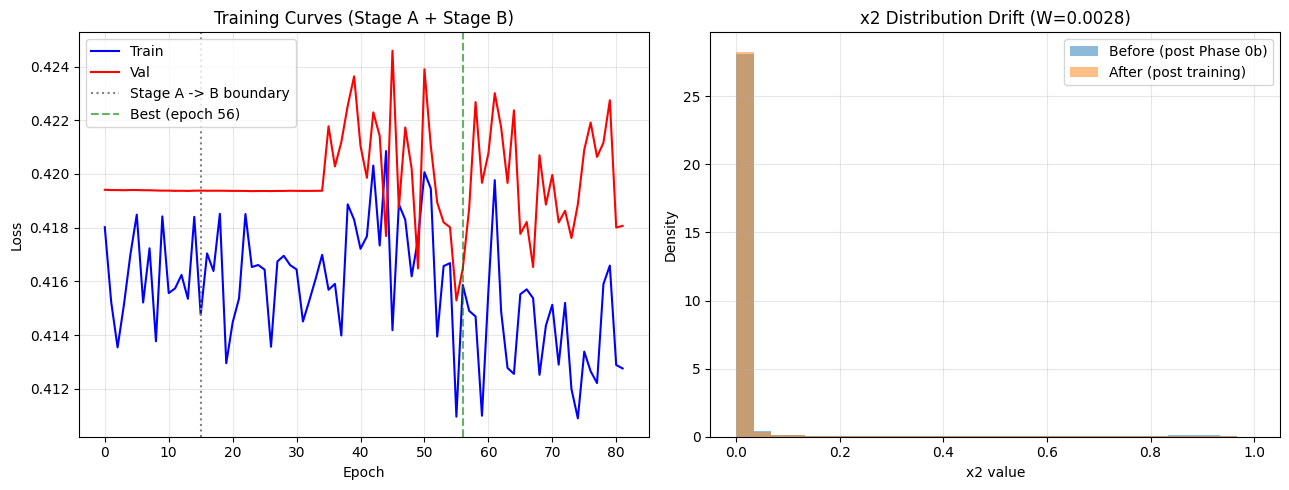

In [17]:
# [DRIFT-ANCHOR, added] Anchor targets for L_drift, computed once from the
# Phase-0b snapshot (x2_dist_before) -- the same distribution the FCM rules
# were fitted on. Plain floats, not tensors: these are fixed targets, never
# themselves trained.
X2_MEAN_ANCHOR = float(x2_dist_before.mean())
X2_STD_ANCHOR  = float(x2_dist_before.std())
print(f'[drift-anchor] targets captured: x2 mean={X2_MEAN_ANCHOR:.4f} std={X2_STD_ANCHOR:.4f}')


def set_trainable(params, trainable: bool):
    for p in params:
        p.requires_grad = trainable

def set_bn_eval(module):
    for m in module.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.eval()

def set_bn_train(module):
    for m in module.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.train()

encoder_modules = [model.enc1, model.enc2, model.enc3, model.enc4, model.bot]
decoder_modules = [model.smoe2, model.smoe3, model.smoe4,
                   model.up4, model.dec4, model.up3, model.dec3,
                   model.up2, model.dec2, model.up1, model.dec1, model.unet_head]


def train_one_epoch_stageA(model, loader, optimizer, criterion, device):
    model.train()
    for m in encoder_modules + decoder_modules:
        set_bn_eval(m)
    running = 0.0
    for imgs, masks, _ in tqdm(loader, desc='  StageA train', leave=False):
        imgs, masks = imgs.to(device, non_blocking=True), masks.to(device, non_blocking=True)
        optimizer.zero_grad()
        prob, rule_maps, _, _, _, _ = model(imgs)
        if prob.dim() == 3: prob = prob.unsqueeze(1)
        # [ADDED] rule-utilization regularizer -- ANFIS/MF params are already
        # trainable in Stage A, so rule collapse can begin forming here too.
        l_util = rule_utilization_loss(rule_maps)
        loss = criterion(prob, masks) + LAMBDA_RULE_UTIL * l_util
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP_NORM)
        optimizer.step()
        running += loss.item()
    return running / len(loader)


def train_one_epoch_stageB(model, loader, optimizer, criterion, device, alpha, encoder_frozen, drift_active):
    model.train()
    if encoder_frozen:
        for m in encoder_modules:
            set_bn_eval(m)
    else:
        for m in encoder_modules:
            set_bn_train(m)
    # [FIXED v5] decoder BN used to be train-mode even while the decoder was
    # frozen (epochs 1..DECODER_UNFREEZE_EPOCH), so running stats kept moving and
    # x2 drifted away from the FCM-fitted geometry despite requires_grad=False.
    # `drift_active` == "decoder/x2_head unfrozen".
    for m in decoder_modules:
        if drift_active: set_bn_train(m)
        else:            set_bn_eval(m)

    running, running_drift, running_util = 0.0, 0.0, 0.0
    for imgs, masks, _ in tqdm(loader, desc='  StageB train', leave=False):
        imgs, masks = imgs.to(device, non_blocking=True), masks.to(device, non_blocking=True)
        optimizer.zero_grad()
        prob, rule_maps, x2, _, unet_logits, _ = model(imgs)
        if prob.dim() == 3: prob = prob.unsqueeze(1)
        l_backbone = criterion(torch.sigmoid(unet_logits), masks)
        l_anfis    = criterion(prob, masks)

        # [DRIFT-ANCHOR, added] Only meaningful once x2_head is actually
        # trainable -- while frozen, x2 physically cannot move, so this would
        # just be near-constant noise in the loss. Anchors x2's batch mean/std
        # back toward the Phase-0b snapshot instead of letting it drift freely
        # once unfrozen (this is what turns "delayed unfreeze" into "delayed
        # AND then gently held in place", the missing half of the fix).
        if drift_active:
            l_drift = (x2.mean() - X2_MEAN_ANCHOR).abs() + (x2.std() - X2_STD_ANCHOR).abs()
        else:
            l_drift = torch.zeros((), device=device)

        # [ADDED] rule-utilization regularizer -- see rule_utilization_loss()
        # docstring. Applied every Stage-B epoch (ANFIS params are trainable
        # throughout Stage B, MF params from MF_FREEZE_EPOCHS onward).
        l_util = rule_utilization_loss(rule_maps)

        loss = alpha * l_backbone + (1 - alpha) * l_anfis + LAMBDA_DRIFT * l_drift + LAMBDA_RULE_UTIL * l_util
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP_NORM)
        optimizer.step()
        running += loss.item()
        running_drift += l_drift.item()
        running_util += l_util.item()
    return running / len(loader), running_drift / len(loader), running_util / len(loader)


def validate_epoch(model, loader, criterion, device):
    model.eval()
    running = 0.0
    with torch.no_grad():
        for imgs, masks, _ in tqdm(loader, desc='  val', leave=False):
            masks = masks.to(device, non_blocking=True)
            pred  = predict_native(model, imgs, device, which='anfis')
            running += criterion(pred, masks).item()
    return running / len(loader)


@torch.no_grad()
def print_rule_diagnostics(model, loader, device, n_batches=15, tag=''):
    wbars = []
    model.eval()
    for i, (imgs, _, _) in enumerate(loader):
        if i >= n_batches: break
        imgs_pad, H, W = pad_to_multiple(imgs.to(device), multiple=PAD_MULTIPLE)
        _, wbar, _, _, _, _ = model(imgs_pad)
        wbars.append(wbar[..., :H, :W].cpu())
    mean_w, max_w, dom_pct = rule_activation_diagnostics(wbars)
    print(f'  [rule diagnostics{tag}] ' +
          '  '.join(f'R{k+1}: fire={mean_w[k]:.2f} dom={dom_pct[k]:.0f}%' for k in range(len(mean_w))))
    if dom_pct.max() > 95:
        print('    WARNING: possible rule collapse (one rule >95% dominant).')


# [ADDED] Resume support: restore model/optimizer/scheduler state, loss
# history, best-weight tracking, and which stage/epoch to resume at, from
# a checkpoint if one exists. The existing in-memory best_state_dict
# tracking below is unchanged -- this only adds where it can be restored
# FROM after a session restart.
if 'CKPT_TRAIN' not in globals(): CKPT_TRAIN = 'training_state_v5.pt'
_train_ckpt = load_checkpoint(CKPT_TRAIN)
if _train_ckpt is not None:
    model.load_state_dict(_train_ckpt['model_state'])
    optimizer.load_state_dict(_train_ckpt['optimizer_state'])
    scheduler.load_state_dict(_train_ckpt['scheduler_state'])
    train_losses = _train_ckpt['train_losses']
    val_losses = _train_ckpt['val_losses']
    best_val_loss = _train_ckpt['best_val_loss']
    best_epoch = _train_ckpt['best_epoch']
    best_state_dict = _train_ckpt['best_state_dict']
    _patience_ctr_resume = _train_ckpt['patience_ctr']
    if _train_ckpt['stage'] == 'A':
        _stageA_start_epoch = _train_ckpt['epoch'] + 1
        _stageB_start_epoch = 1
    else:
        _stageA_start_epoch = FROZEN_BASELINE_EPOCHS + 1
        _stageB_start_epoch = _train_ckpt['epoch'] + 1
    print(f"[resume] Training restored from checkpoint -- stage={_train_ckpt['stage']} "
          f"epoch={_train_ckpt['epoch']} best_val_loss={best_val_loss:.4f}")
else:
    train_losses, val_losses = [], []
    best_val_loss, best_epoch = float('inf'), 0
    best_state_dict = None   # kept IN MEMORY, same as before [UNCHANGED]
    _patience_ctr_resume = 0
    _stageA_start_epoch = 1
    _stageB_start_epoch = 1

# ---------------------------------------------------------------------------
# STAGE A -- frozen baseline
# ---------------------------------------------------------------------------
print('='*72)
print(f'STAGE A -- genuinely frozen backbone baseline ({FROZEN_BASELINE_EPOCHS} epochs)')
print('='*72)
set_trainable(encoder_params, False)
set_trainable(decoder_params, False)
set_trainable(anfis_params,   True)
set_trainable(mf_params,      True)

for epoch in range(_stageA_start_epoch, FROZEN_BASELINE_EPOCHS + 1):
    model.anfis_head.update_sigma_ceiling()   # sigma ceiling: refresh from current centers
    tl = train_one_epoch_stageA(model, loader_train, optimizer, criterion, DEVICE)
    vl = validate_epoch(model, loader_val, criterion, DEVICE)
    train_losses.append(tl); val_losses.append(vl)
    print(f'  [StageA] epoch {epoch:3d}/{FROZEN_BASELINE_EPOCHS}  train={tl:.4f}  val={vl:.4f}')
    if vl < best_val_loss:
        best_val_loss, best_epoch = vl, epoch
        best_state_dict = copy.deepcopy(model.state_dict())   # in-memory only [UNCHANGED]

    # [ADDED] per-epoch checkpoint save point (Stage A)
    save_checkpoint({
        'stage': 'A', 'epoch': epoch,
        'model_state': model.state_dict(),
        'optimizer_state': optimizer.state_dict(),
        'scheduler_state': scheduler.state_dict(),
        'train_losses': train_losses, 'val_losses': val_losses,
        'best_val_loss': best_val_loss, 'best_epoch': best_epoch,
        'patience_ctr': 0, 'best_state_dict': best_state_dict,
    }, CKPT_TRAIN)

print(f'\nStage A complete. Best val loss so far: {best_val_loss:.4f}')

# ---------------------------------------------------------------------------
# STAGE B -- joint fine-tuning, gradual unfreeze
# ---------------------------------------------------------------------------
print('\n' + '='*72)
print(f'STAGE B -- joint fine-tuning, up to {MAX_EPOCHS} epochs, gradual unfreeze')
print('='*72)
set_trainable(decoder_params, False)   # FIX: was unconditionally True from epoch 1
set_trainable(x2_head_params, False)   # [DRIFT-ANCHOR, added] same protection as decoder_params
set_trainable(anfis_params,   True)
patience_ctr = _patience_ctr_resume   # [CHANGED] resume the counter instead of always 0

for epoch in range(_stageB_start_epoch, MAX_EPOCHS + 1):
    mf_frozen = epoch <= MF_FREEZE_EPOCHS
    set_trainable(mf_params, not mf_frozen)

    encoder_frozen = epoch <= ENCODER_UNFREEZE_EPOCH
    set_trainable(encoder_params, not encoder_frozen)

    # FIX: decoder (unet_head -> x2) now protected on its own schedule instead
    # of being trainable from Stage-B epoch 1 -- this was the earliest, most
    # direct source of x2 drift relative to the FCM-fitted geometry.
    decoder_frozen = epoch <= DECODER_UNFREEZE_EPOCH
    set_trainable(decoder_params, not decoder_frozen)
    set_trainable(x2_head_params, not decoder_frozen)   # [DRIFT-ANCHOR, added]

    model.anfis_head.update_sigma_ceiling()   # sigma ceiling: refresh from current centers

    if epoch == 1:
        print(f'  MF params frozen for Stage-B epochs 1-{MF_FREEZE_EPOCHS}')
        print(f'  Encoder frozen (weights+BN) for Stage-B epochs 1-{ENCODER_UNFREEZE_EPOCH}, '
              f'then unfreezes at lr={LR_ENCODER}')
        print(f'  Decoder (smoe/up/dec) frozen for Stage-B epochs 1-{DECODER_UNFREEZE_EPOCH}, '
              f'then unfreezes at lr={LR_DECODER}')
        print(f'  [DRIFT-ANCHOR] x2_head (unet_head) frozen for Stage-B epochs 1-{DECODER_UNFREEZE_EPOCH}, '
              f'then unfreezes at lr={LR_X2_HEAD} (10x smaller than decoder) with L_drift active '
              f'(lambda={LAMBDA_DRIFT}, anchored to x2 mean={X2_MEAN_ANCHOR:.4f} std={X2_STD_ANCHOR:.4f})')
    if epoch == ENCODER_UNFREEZE_EPOCH + 1:
        print(f'  >>> Encoder unfrozen at Stage-B epoch {epoch} (lr={LR_ENCODER})')
    if epoch == DECODER_UNFREEZE_EPOCH + 1:
        print(f'  >>> Decoder unfrozen at Stage-B epoch {epoch} (lr={LR_DECODER})')
        print(f'  >>> [DRIFT-ANCHOR] x2_head unfrozen at Stage-B epoch {epoch} '
              f'(lr={LR_X2_HEAD}, L_drift now active)')

    tl, drift_avg, util_avg = train_one_epoch_stageB(model, loader_train, optimizer, criterion, DEVICE,
                                ALPHA_BACKBONE, encoder_frozen, drift_active=not decoder_frozen)
    vl = validate_epoch(model, loader_val, criterion, DEVICE)
    train_losses.append(tl); val_losses.append(vl)
    scheduler.step(vl)

    if vl < best_val_loss:
        best_val_loss, best_epoch, patience_ctr = vl, len(train_losses), 0
        best_state_dict = copy.deepcopy(model.state_dict())   # in-memory only [UNCHANGED]
        status = 'BEST'
    else:
        patience_ctr += 1
        status = f'pat {patience_ctr}/{PATIENCE}'

    # [ADDED] per-epoch checkpoint save point (Stage B)
    save_checkpoint({
        'stage': 'B', 'epoch': epoch,
        'model_state': model.state_dict(),
        'optimizer_state': optimizer.state_dict(),
        'scheduler_state': scheduler.state_dict(),
        'train_losses': train_losses, 'val_losses': val_losses,
        'best_val_loss': best_val_loss, 'best_epoch': best_epoch,
        'patience_ctr': patience_ctr, 'best_state_dict': best_state_dict,
    }, CKPT_TRAIN)

    if epoch % 10 == 0 or epoch == 1:
        lrs = [f'{g["name"]}={g["lr"]:.1e}' for g in optimizer.param_groups]
        print(f'  [StageB] epoch {epoch:4d} train={tl:.4f} val={vl:.4f} {" ".join(lrs)}  {status}')

    # [DRIFT-ANCHOR, added] Live drift-loss trend, separate from the final
    # before/after Wasserstein report -- lets you see whether L_drift is
    # actually shrinking (x2 settling near its anchor) or growing (anchor
    # too weak / LR_X2_HEAD still too high) well before training finishes.
    if not decoder_frozen and epoch % DRIFT_REPORT_EVERY_N_EPOCHS == 0:
        print(f'  [drift-anchor] epoch {epoch:4d}  L_drift={drift_avg:.5f}  '
              f'(target x2 mean={X2_MEAN_ANCHOR:.4f} std={X2_STD_ANCHOR:.4f})')

    if epoch % RULE_DIAG_EVERY_N_EPOCHS == 0:
        print_rule_diagnostics(model, loader_val, DEVICE, tag=f' @ StageB epoch {epoch}')
        log_rule_geometry(model.anfis_head, tag=f' @ StageB epoch {epoch}')
        # [ADDED] observability for the new regularizer: 0=balanced usage, 1=collapse
        print(f'  [rule-util loss] epoch {epoch:4d}  L_util={util_avg:.4f}  (0=balanced, 1=full collapse)')

    if patience_ctr >= PATIENCE:
        print(f'\nEarly stopping at Stage-B epoch {epoch}')
        break

# Restore best weights (in-memory swap, nothing written to disk)
if best_state_dict is not None:
    model.load_state_dict(best_state_dict)
print(f'\nBest val loss: {best_val_loss:.4f} at global epoch {best_epoch} (best weights restored from memory)')

# Step 1: verify the restored weights genuinely belong to THIS run, not a
# stale reference -- prints a checksum of the loaded state_dict plus the
# actual consequent/sigma-ceiling values, so results can be compared across
# runs to confirm they differ when training genuinely differs. Read-only.
_state_bytes = b''.join(p.detach().cpu().numpy().tobytes() for p in model.parameters())
_state_checksum = hashlib.md5(_state_bytes).hexdigest()[:12]
print(f'Loaded-weights checksum: {_state_checksum}  (best_epoch={best_epoch})')
log_rule_geometry(model.anfis_head, tag=' (post-training, restored best weights)')
print(f'ANFIS consequents (restored):\n{model.anfis_head.consequents.detach().cpu().numpy()}')

# Feature-drift snapshot AFTER training (compare against the Phase-0b baseline)
with torch.no_grad():
    x2_after_list = []
    for i, (imgs, _, _) in enumerate(loader_val):
        if i >= FEATURE_DRIFT_N_BATCHES: break
        imgs_pad, H, W = pad_to_multiple(imgs.to(DEVICE), multiple=PAD_MULTIPLE)
        _, _, x2_map, _, _, _ = model(imgs_pad)
        x2_after_list.append(x2_map[..., :H, :W].cpu().flatten())
x2_dist_after = torch.cat(x2_after_list).numpy()

w_dist = wasserstein_distance(x2_dist_before, x2_dist_after)
hist_before, edges = np.histogram(x2_dist_before, bins=30, range=(0,1), density=True)
hist_after, _      = np.histogram(x2_dist_after,  bins=edges, density=True)
kl = float(np.sum(np.where(hist_before > 0,
                           hist_before * np.log((hist_before + 1e-8) / (hist_after + 1e-8)), 0)) * (edges[1]-edges[0]))

print('\n' + '='*72)
print('FEATURE-DRIFT REPORT -- x2 = sigmoid(unet_logits), before vs after backbone fine-tuning')
print('='*72)
print(f'  Before (post Phase-0b) : mean={x2_dist_before.mean():.4f}  std={x2_dist_before.std():.4f}')
print(f'  After  (post training) : mean={x2_dist_after.mean():.4f}  std={x2_dist_after.std():.4f}')
print(f'  Wasserstein distance   : {w_dist:.4f}')
print(f'  Approx. KL(before||after): {kl:.4f}')
if w_dist > 0.05:
    print('  NOTE: noticeable drift -- the FCM rule geometry was fit on a feature')
    print('  space that has since moved; consider a smaller LR_ENCODER or an')
    print('  earlier ENCODER_UNFREEZE_EPOCH if downstream metrics look off.')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(train_losses, 'b-', lw=1.5, label='Train')
axes[0].plot(val_losses,   'r-', lw=1.5, label='Val')
axes[0].axvline(FROZEN_BASELINE_EPOCHS, color='gray', ls=':', label='Stage A -> B boundary')
axes[0].axvline(best_epoch, color='g', ls='--', alpha=0.6, label=f'Best (epoch {best_epoch})')
axes[0].set(xlabel='Epoch', ylabel='Loss', title='Training Curves (Stage A + Stage B)')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].hist(x2_dist_before, bins=30, range=(0,1), alpha=0.5, label='Before (post Phase 0b)', density=True)
axes[1].hist(x2_dist_after,  bins=30, range=(0,1), alpha=0.5, label='After (post training)', density=True)
axes[1].set(xlabel='x2 value', ylabel='Density', title=f'x2 Distribution Drift (W={w_dist:.4f})')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{WORK_DIR}/training_curves_and_drift.png', dpi=150)
plt.show()


## Cell — Evaluation: ODS / OIS / AP
### v6: `standard` protocol (NMS thinning + per-annotator matching) reported alongside the v4/v5 `legacy` protocol; optional flip-TTA rows; Sobel calibration check.



Computing test-set metrics...


Inference (anfis+MS-TTA8): 100%|██████████| 200/200 [18:26<00:00,  5.53s/it]


  [saved test predictions] /kaggle/working/smoe_results_v4/preds/anfis_ms8.npz


Matching [standard]: 100%|██████████| 200/200 [58:37<00:00, 17.59s/it]  


  NOTE: prediction cap binds for 52/200 images at the lowest threshold and for 0/200 at the ODS-optimal threshold (0.01).
anfis   [standard+MS-TTA(8-fold)]  ODS=0.7586  OIS=0.7745  AP(full)=0.8039  AP(reached)=0.8171  best_t=0.01  max_recall=0.966
                                   95% CI (test-image bootstrap): ODS [0.7441, 0.7725]  OIS [0.7621, 0.7863]  AP [0.7887, 0.8178]
                                   classic grid 0.01-0.99 only: ODS=0.7586  OIS=0.7633  AP(full)=0.7025


...

  [saved test predictions] /kaggle/working/smoe_results_v4/preds/backbone_ms8.npz


Matching [standard]: 100%|██████████| 200/200 [56:09<00:00, 16.85s/it]  


  NOTE: prediction cap binds for 16/200 images at the lowest threshold and for 0/200 at the ODS-optimal threshold (0.01).
backbone[standard+MS-TTA(8-fold)]  ODS=0.7581  OIS=0.7743  AP(full)=0.7965  AP(reached)=0.8099  best_t=0.01  max_recall=0.949
                                   95% CI (test-image bootstrap): ODS [0.7438, 0.7726]  OIS [0.7617, 0.7863]  AP [0.7815, 0.8113]
                                   classic grid 0.01-0.99 only: ODS=0.7581  OIS=0.7648  AP(full)=0.7102


Matching [standard]: 100%|██████████| 200/200 [59:19<00:00, 17.80s/it]  


  NOTE: prediction cap binds for 16/200 images at the lowest threshold and for 0/200 at the ODS-optimal threshold (0.01).
backbone[standard+MS-TTA(8-fold)+maxnorm] ODS=0.7575  OIS=0.7743  AP(full)=0.7962  AP(reached)=0.8023  best_t=0.01  max_recall=0.949
                                   95% CI (test-image bootstrap): ODS [0.7441, 0.7724]  OIS [0.7617, 0.7863]  AP [0.7807, 0.8127]
                                   classic grid 0.01-0.99 only: ODS=0.7575  OIS=0.7659  AP(full)=0.7170

ANFIS - Backbone [ms8] (paired bootstrap): ODS +0.0003 [-0.0007, 0.0009]  OIS +0.0002 [-0.0002, 0.0007]  AP_full +0.0066 [0.0040, 0.0088]


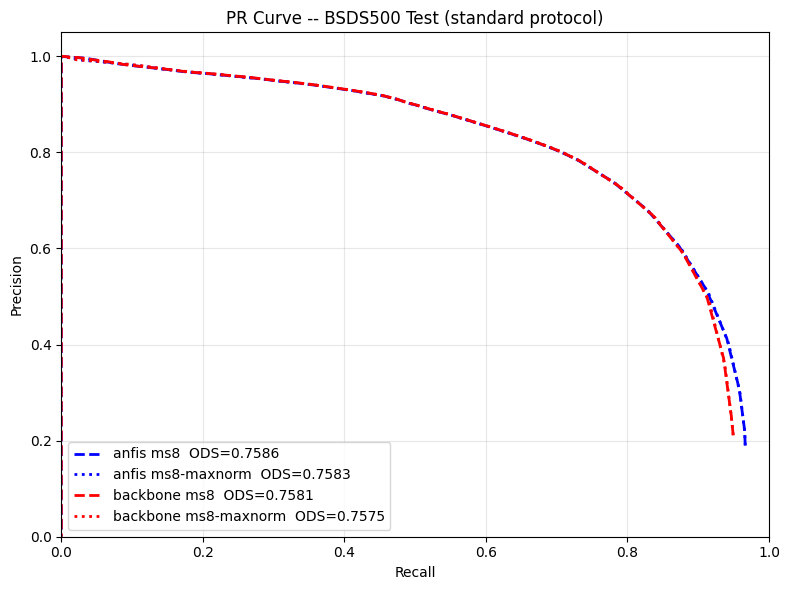

In [18]:
from scipy.optimize import linear_sum_assignment
from scipy.spatial  import cKDTree
from scipy.sparse   import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.ndimage  import gaussian_filter, map_coordinates
import glob, concurrent.futures, multiprocessing as mp

N_WORKERS = min(os.cpu_count() or 4, 4)
MAX_PRED  = 15000          # legacy protocol cap (unchanged)

# [ADDED v8] Threshold grid + cap for the STANDARD protocol.
# v7 logs: best_t = 0.010 (the LOWEST grid point) in all six rows and max recall only 0.75-0.77, i.e. the
# optimum lay at/below the grid edge and AP(full) was zero-filled beyond the reached recall. ODS/AP depend on
# ranking only, so the grid must bracket the optimum: add log-spaced points below 0.01 (fixed a priori, no
# test-set tuning, no per-image normalisation) and a boundary check that warns if it still does not.
def make_thresholds(n_lin=99, extend=True):
    lin = np.linspace(0.01, 0.99, n_lin)
    if not extend:
        return lin
    n_low = int(globals().get('EVAL_N_LOW', 8)); t_low = float(globals().get('EVAL_T_LOW', 1e-4))
    low = np.geomspace(t_low, 0.01, n_low, endpoint=False)
    return np.concatenate([low, lin])

# ---------------------------------------------------------------------------
# Ground truth loading (unchanged from v4/v5)
# ---------------------------------------------------------------------------
def load_gt_boundaries(mat_path):
    boundaries = []
    try:
        mat = scipy.io.loadmat(mat_path, squeeze_me=True)
        gt_cell = mat['groundTruth']
        if gt_cell.ndim == 0:
            gt_cell = gt_cell.reshape(1)
        for ann in gt_cell.flat:
            try:
                b = ann['Boundaries'] if isinstance(ann, np.void) else ann[()]['Boundaries']
            except (KeyError, TypeError, IndexError):
                b = ann[0, 0][1] if hasattr(ann, '__getitem__') else ann.Boundaries
            if hasattr(b, 'toarray'):
                b = b.toarray()
            boundaries.append(b.astype(np.float32))
        return boundaries
    except Exception:
        return []


# ---------------------------------------------------------------------------
# [ADDED v6] Ridge-based non-maximum suppression (thinning).
# Simplified re-implementation of the idea behind Dollar's edgesNms: estimate the
# across-edge direction from the Hessian of the smoothed map, keep a pixel only if
# it is a local maximum along that direction. Differences from the MATLAB toolbox:
# Gaussian (not triangle) smoothing, no image-border suppression term.
# Computed ONCE per image; thresholds then just select pixels of the thinned map.
# ---------------------------------------------------------------------------
def edge_nms(prob, sigma=2.0, radius=1, mult=1.01):
    E = prob.astype(np.float32)
    a = gaussian_filter(E, sigma, order=(0, 2))    # d2/dx2   (axis0=y, axis1=x)
    c = gaussian_filter(E, sigma, order=(2, 0))    # d2/dy2
    b = gaussian_filter(E, sigma, order=(1, 1))    # d2/dxdy
    half = 0.5 * (a + c)
    rad  = np.sqrt((0.5 * (a - c)) ** 2 + b ** 2)
    lam1, lam2 = half + rad, half - rad
    th1   = 0.5 * np.arctan2(2.0 * b, a - c)       # (x,y) direction of eigvec for lam1
    theta = np.where(np.abs(lam1) >= np.abs(lam2), th1, th1 + np.pi / 2)   # across-ridge
    dx, dy = np.cos(theta), np.sin(theta)
    H, W = E.shape
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    keep = np.ones((H, W), dtype=bool)
    e = E * mult
    for d in range(1, radius + 1):
        for sgn in (-1.0, 1.0):
            nb = map_coordinates(E, [yy + sgn * d * dy, xx + sgn * d * dx],
                                 order=1, mode='nearest')
            keep &= (e >= nb)
    return np.where(keep, E, 0.0).astype(np.float32)


# ---------------------------------------------------------------------------
# Bipartite matching (same algorithm as v4/v5; now also returns WHICH predicted
# pixels were matched, needed for the per-annotator precision definition).
# ---------------------------------------------------------------------------
def _sparse_bipartite_tp(pred_yx, gt_yx, gt_tree, maxDist):
    n_pred = len(pred_yx); n_gt = len(gt_yx)
    empty = np.zeros(0, dtype=np.int64)
    if n_pred == 0 or n_gt == 0:
        return 0.0, empty
    neighbors = gt_tree.query_ball_point(pred_yx, r=maxDist)
    pred_idx_list, gt_idx_list, dist_list = [], [], []
    for pi, gts in enumerate(neighbors):
        if not gts: continue
        gy = gt_yx[gts]
        d  = np.sqrt(((gy - pred_yx[pi]) ** 2).sum(-1))
        for gj, dd in zip(gts, d):
            pred_idx_list.append(pi); gt_idx_list.append(gj); dist_list.append(dd)
    if not pred_idx_list:
        return 0.0, empty
    pred_idx_arr = np.array(pred_idx_list); gt_idx_arr = np.array(gt_idx_list)
    dist_arr = np.array(dist_list)
    n_total = n_pred + n_gt
    rows = np.concatenate([pred_idx_arr, gt_idx_arr + n_pred])
    cols = np.concatenate([gt_idx_arr + n_pred, pred_idx_arr])
    data = np.ones(len(rows))
    graph = coo_matrix((data, (rows, cols)), shape=(n_total, n_total))
    _, labels = connected_components(graph, directed=False)
    pred_labels = labels[:n_pred]
    edge_comp = pred_labels[pred_idx_arr]
    tp = 0.0
    matched = []
    for comp_id in np.unique(edge_comp):
        mask = edge_comp == comp_id
        p_local_ids = np.unique(pred_idx_arr[mask]); g_local_ids = np.unique(gt_idx_arr[mask])
        p_map = {p: k for k, p in enumerate(p_local_ids)}
        g_map = {g: k for k, g in enumerate(g_local_ids)}
        r, c = len(p_local_ids), len(g_local_ids)
        cost = np.full((r, c), 1e9)
        for p, g, d in zip(pred_idx_arr[mask], gt_idx_arr[mask], dist_arr[mask]):
            cost[p_map[p], g_map[g]] = d
        row_ind, col_ind = linear_sum_assignment(cost)
        valid = cost[row_ind, col_ind] < maxDist
        tp += float(valid.sum())
        matched.append(p_local_ids[row_ind[valid]])
    matched = np.concatenate(matched) if matched else empty
    return tp, matched


# ---------------------------------------------------------------------------
# Counts at every threshold for ONE image.
#   protocol='legacy'   : v4/v5 behaviour -- raw (unthinned) map, GT = union of
#                         annotators, single 1:1 match, maxDist = .0075*max(H,W).
#   protocol='standard' : thinned map (edge_nms); every annotator matched
#                         separately; recall = sum matched GT px / sum GT px over
#                         annotators; precision = predicted px matched to >=1
#                         annotator / predicted px; maxDist = .0075*image diagonal.
# Both return (cntP, sumP, cntR, sumR) so one aggregation covers both.
# ---------------------------------------------------------------------------
def counts_at_thresholds(prob, gt_boundaries, thresholds, protocol='standard'):
    H, W = prob.shape
    n_thresh = len(thresholds)
    if protocol == 'standard':
        maxDist = max(0.0075 * float(np.hypot(H, W)), 1.0)
        gts = [(b > 0.5) for b in gt_boundaries]
        prob_eval = edge_nms(prob, sigma=NMS_SIGMA)
        cap = int(globals().get('MAX_PRED_STANDARD', 30000))
    else:
        maxDist = max(0.0075 * max(H, W), 1.0)
        gts = [(np.stack(gt_boundaries, 0).max(0) > 0.5)]
        prob_eval = prob
        cap = MAX_PRED
    gts = [g for g in gts if g.any()]
    cntP = np.zeros(n_thresh); sumP = np.zeros(n_thresh)
    cntR = np.zeros(n_thresh); sumR = np.zeros(n_thresh)
    if not gts:
        for i, t in enumerate(thresholds):
            sumP[i] = float((prob_eval >= t).sum())
        return cntP, sumP, cntR, sumR, np.zeros(n_thresh, dtype=bool)
    gt_yx_list = [np.column_stack(np.where(g)).astype(np.float32) for g in gts]
    trees      = [cKDTree(y) for y in gt_yx_list]
    n_gt_total = float(sum(len(y) for y in gt_yx_list))
    sumR[:] = n_gt_total
    capped_arr = np.zeros(n_thresh, dtype=bool)   # [v9] where the prediction cap bound
    capped_prev = None
    for i, t in enumerate(thresholds):
        pred_edge = (prob_eval >= t)
        if not pred_edge.any():
            continue
        pred_yx = np.column_stack(np.where(pred_edge)).astype(np.float32)
        _is_capped = len(pred_yx) > cap
        if _is_capped:
            # keep the `cap` most CONFIDENT predictions (no GT information used)
            capped_arr[i] = True
            if capped_prev is not None:
                # same top-`cap` set as an earlier (lower) threshold -> identical counts; skip the re-match
                cntP[i], sumP[i], cntR[i] = cntP[capped_prev], sumP[capped_prev], cntR[capped_prev]
                continue
            pred_conf = prob_eval[pred_edge]
            pred_yx = pred_yx[np.argsort(-pred_conf)[:cap]]
        n_pred = len(pred_yx)
        matched_any = np.zeros(n_pred, dtype=bool)
        for gt_yx, tree in zip(gt_yx_list, trees):
            tp_g, m = _sparse_bipartite_tp(pred_yx, gt_yx, tree, maxDist)
            cntR[i] += tp_g
            if len(m): matched_any[m] = True
        cntP[i] = float(matched_any.sum())
        sumP[i] = float(n_pred)
        if _is_capped: capped_prev = i
    return cntP, sumP, cntR, sumR, capped_arr


def _image_counts_worker(args):
    prob, mat_path, gt_fallback, thresholds, protocol = args
    gt_bnd = load_gt_boundaries(mat_path) if (mat_path and os.path.exists(mat_path)) else []
    used_fallback = False
    if not gt_bnd:
        gt_bnd = [gt_fallback]; used_fallback = True      # reported loudly by the caller
    return counts_at_thresholds(prob, gt_bnd, thresholds, protocol), used_fallback


def _prf(cntP, sumP, cntR, sumR):
    P = cntP / (sumP + 1e-8); R = cntR / (sumR + 1e-8)
    return P, R, 2 * P * R / (P + R + 1e-8)


def _ap_full_range(precs, recs):
    """Mean interpolated precision at recall = 0, .01, ..., 1 (precision envelope,
    0 beyond the maximum recall the detector reaches). Penalises curves that stop
    early. Written to follow the usual BSDS convention; not verified bit-identical
    to the MATLAB toolbox."""
    order = np.argsort(recs)
    r, p = recs[order], precs[order]
    env = np.maximum.accumulate(p[::-1])[::-1]
    grid = np.linspace(0, 1, 101)
    vals = [env[np.searchsorted(r, g, side='left')] if g <= r[-1] else 0.0 for g in grid]
    return float(np.mean(vals))


# ---------------------------------------------------------------------------
# Inference helpers
# ---------------------------------------------------------------------------
@torch.no_grad()
def predict_tta(model, img, device, which='anfis', scales=(1.0,), dihedral=False):
    """Mean over `scales` x 4 flips (x2 transposes if dihedral=True -> 8 views per scale). Every view is
    mapped back to the original orientation/size before averaging. Inference-only; no parameter changes.
    The 8 dihedral views are all in-distribution (training used 90-degree rotations and flips)."""
    H, W = img.shape[-2:]
    acc, n = None, 0
    for s in scales:
        xs = img if s == 1.0 else F.interpolate(
            img, size=(max(int(round(H * s)), 32), max(int(round(W * s)), 32)),
            mode='bilinear', align_corners=False)
        for tp in ((False, True) if dihedral else (False,)):
            for hf in (False, True):
                for vf in (False, True):
                    x = xs
                    if tp: x = x.transpose(-1, -2).contiguous()
                    if hf: x = torch.flip(x, dims=[-1])
                    if vf: x = torch.flip(x, dims=[-2])
                    p = predict_native(model, x, device, which=which)
                    if vf: p = torch.flip(p, dims=[-2])
                    if hf: p = torch.flip(p, dims=[-1])
                    if tp: p = p.transpose(-1, -2)
                    p = p.reshape(1, 1, p.shape[-2], p.shape[-1]).float()
                    if s != 1.0:
                        p = F.interpolate(p, size=(H, W), mode='bilinear', align_corners=False)
                    acc = p if acc is None else acc + p
                    n += 1
    return acc / n


@torch.no_grad()
def collect_predictions(model, loader, device, which='anfis', tta=False, scales=(1.0,), dihedral=False):
    model.eval()
    preds = []
    _lab = f'{which}' + ('' if not tta else ('+MS-TTA' if tuple(scales) != (1.0,) else '+TTA') + ('8' if dihedral else ''))
    for imgs, masks, stems in tqdm(loader, desc=f'Inference ({_lab})'):
        if tta:
            pred = predict_tta(model, imgs, device, which=which, scales=scales, dihedral=dihedral)
        else:
            pred = predict_native(model, imgs, device, which=which)
        prob = pred.squeeze().cpu().numpy().astype(np.float32)
        gt_b = (masks.squeeze().cpu().numpy() > 0.5).astype(np.float32)
        stem = stems[0] if isinstance(stems, (list, tuple)) else stems
        preds.append((prob, stem, gt_b))
    return preds


def score_predictions(preds, protocol='standard', n_thresh=99, split='test'):
    thresholds = make_thresholds(n_thresh, extend=(protocol == 'standard'))
    gt_dir = os.path.join(BSR_ROOT, 'data', 'groundTruth', split)
    jobs = [(prob, os.path.join(gt_dir, f'{stem}.mat'), gt_b, thresholds, protocol)
            for prob, stem, gt_b in preds]
    results = None
    try:   # CPU-bound pure-python matching: processes (fork) beat threads (GIL)
        ctx = mp.get_context('fork')
        with concurrent.futures.ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx) as ex:
            results = list(tqdm(ex.map(_image_counts_worker, jobs, chunksize=2),
                                total=len(jobs), desc=f'Matching [{protocol}]'))
    except Exception as e:
        print(f'  [matching] process pool unavailable ({type(e).__name__}); falling back to threads')
    if results is None:
        with concurrent.futures.ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
            results = list(tqdm(ex.map(_image_counts_worker, jobs), total=len(jobs),
                                desc=f'Matching [{protocol}] (threads)'))
    n_fb = sum(1 for _, fb in results if fb)
    if n_fb:
        print(f'  WARNING: GT .mat could not be parsed for {n_fb}/{len(results)} images -- those used the '
              f'single binary fallback mask, so the protocol is NOT what it claims for them.')
    per_image = [r for r, _ in results]
    cP_i = np.stack([r[0] for r in per_image]); sP_i = np.stack([r[1] for r in per_image])
    cR_i = np.stack([r[2] for r in per_image]); sR_i = np.stack([r[3] for r in per_image])
    capped = np.stack([r[4] for r in per_image])
    precs, recs, fscs = _prf(cP_i.sum(0), sP_i.sum(0), cR_i.sum(0), sR_i.sum(0))
    best_i = int(np.argmax(fscs))
    img_best_f = np.array([_prf(cP_i[j], sP_i[j], cR_i[j], sR_i[j])[2].max() for j in range(len(per_image))])
    n_cap_low, n_cap_best = int(capped[:, 0].sum()), int(capped[:, best_i].sum())
    if best_i == 0:
        print(f'  WARNING: best threshold ({thresholds[0]:.2g}) is the LOWEST grid point -- the optimum may lie below '
              f'it; lower EVAL_T_LOW. ODS/AP are still under-estimated.')
    elif best_i == len(thresholds) - 1:
        print('  WARNING: best threshold is the HIGHEST grid point -- extend the grid upward.')
    if n_cap_low or n_cap_best:
        print(f'  NOTE: prediction cap binds for {n_cap_low}/{len(per_image)} images at the lowest threshold and for '
              f'{n_cap_best}/{len(per_image)} at the ODS-optimal threshold ({thresholds[best_i]:.2g}).')
    # [v9] "classic grid" = only the 99 linear thresholds 0.01..0.99 (what v7 reported), from the same counts.
    m = thresholds >= 0.01 - 1e-12
    Pc, Rc, Fc = _prf(cP_i.sum(0)[m], sP_i.sum(0)[m], cR_i.sum(0)[m], sR_i.sum(0)[m])
    ois_c = np.mean([_prf(cP_i[j][m], sP_i[j][m], cR_i[j][m], sR_i[j][m])[2].max() for j in range(len(per_image))])
    classic = dict(ODS=float(Fc.max()), OIS=float(ois_c), AP_full=_ap_full_range(Pc, Rc))
    order = np.argsort(recs)
    try:   AP_reached = float(auc(recs[order], precs[order]))
    except ValueError: AP_reached = 0.0
    return dict(ODS=float(fscs[best_i]), OIS=float(img_best_f.mean()),
                AP_full=_ap_full_range(precs, recs), AP_reached=AP_reached,
                best_t=float(thresholds[best_i]), max_recall=float(recs.max()),
                n_cap_low=n_cap_low, n_cap_best=n_cap_best, classic=classic,
                counts=(cP_i, sP_i, cR_i, sR_i), img_best_f=img_best_f, thresholds=thresholds,
                precs=precs, recs=recs, protocol=protocol)


# ---------------------------------------------------------------------------
# [ADDED v9] Uncertainty from the finite test set: bootstrap over test IMAGES (per-image counts are stored).
# This captures test-sampling noise only -- NOT training-seed variance (needs several trained models).
# ---------------------------------------------------------------------------
def _boot_stats(res, idx):
    cP, sP, cR, sR = res['counts']
    P, R, Fm = _prf(cP[idx].sum(0), sP[idx].sum(0), cR[idx].sum(0), sR[idx].sum(0))
    return float(Fm.max()), float(res['img_best_f'][idx].mean()), _ap_full_range(P, R)

def bootstrap_ci(res, n_boot=1000, seed=0, alpha=0.05):
    N = len(res['img_best_f']); rng = np.random.RandomState(seed)
    out = np.array([_boot_stats(res, rng.randint(0, N, N)) for _ in range(n_boot)])
    q = lambda v: (float(np.percentile(v, 100 * alpha / 2)), float(np.percentile(v, 100 * (1 - alpha / 2))))
    return dict(ODS=q(out[:, 0]), OIS=q(out[:, 1]), AP_full=q(out[:, 2]))

def bootstrap_diff(res_a, res_b, n_boot=1000, seed=0, alpha=0.05):
    """Paired bootstrap (same resampled images for both) of metric(a) - metric(b)."""
    N = len(res_a['img_best_f']); rng = np.random.RandomState(seed)
    d = []
    for _ in range(n_boot):
        idx = rng.randint(0, N, N)
        d.append(np.array(_boot_stats(res_a, idx)) - np.array(_boot_stats(res_b, idx)))
    d = np.array(d)
    q = lambda v: (float(np.percentile(v, 100 * alpha / 2)), float(np.percentile(v, 100 * (1 - alpha / 2))))
    names = ('ODS', 'OIS', 'AP_full')
    return {k: dict(mean=float(d[:, i].mean()), ci=q(d[:, i]), p_pos=float((d[:, i] > 0).mean()))
            for i, k in enumerate(names)}

def score_with_ci(preds, protocol='standard', n_thresh=None):
    res = score_predictions(preds, protocol, n_thresh or EVAL_N_THRESH)
    if EVAL_BOOTSTRAP > 0:
        res['ci'] = bootstrap_ci(res, EVAL_BOOTSTRAP)
    return res

def maxnorm_preds(preds):
    """[v9+] Per-image max-normalisation: p / max(p). Uses the prediction only (no GT), has no free parameter,
    and is monotone within each image, so OIS is unchanged; it only aligns score scales ACROSS images, which is
    what a single global threshold (ODS) needs. It is a post-processing step: disclose it and never mix it with
    un-normalised rows when comparing methods."""
    return [(prob / max(float(prob.max()), 1e-8), stem, gt_b) for prob, stem, gt_b in preds]

def save_preds(preds, path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    np.savez_compressed(path, **{stem: prob.astype(np.float32) for prob, stem, _ in preds})
    print(f'  [saved test predictions] {path}')

def load_preds(path):
    d = np.load(path)
    return {k: d[k] for k in d.files}


# ---------------------------------------------------------------------------
# Sobel as a detector (protocol calibration only) -- uses the model's own calibrated Sobel layer
# ---------------------------------------------------------------------------
@torch.no_grad()
def collect_sobel_predictions(model, loader, device, max_images=None):
    model.eval(); preds = []
    for i, (imgs, masks, stems) in enumerate(tqdm(loader, desc='Inference (sobel)')):
        if max_images is not None and i >= max_images: break
        x_raw = (imgs.to(device) * model.img_std + model.img_mean).clamp(0, 1)
        prob = model.sobel(x_raw).squeeze().cpu().numpy().astype(np.float32)
        gt_b = (masks.squeeze().cpu().numpy() > 0.5).astype(np.float32)
        stem = stems[0] if isinstance(stems, (list, tuple)) else stems
        preds.append((prob, stem, gt_b))
    return preds

RESULTS = {}
MODE_CFG = {'plain': dict(tta=False, scales=(1.0,),         dihedral=False),
            'flip':  dict(tta=True,  scales=(1.0,),         dihedral=False),
            'ms':    dict(tta=True,  scales=EVAL_MS_SCALES, dihedral=False),
            'ms8':   dict(tta=True,  scales=EVAL_MS_SCALES, dihedral=True)}
_MODE_TAG = {'plain': '', 'flip': '+TTA', 'ms': '+MS-TTA', 'ms8': '+MS-TTA(8-fold)'}

def _fmt_ci(ci): return f'[{ci[0]:.4f}, {ci[1]:.4f}]'
def _report(tag, r):
    print(f'{tag:<34} ODS={r["ODS"]:.4f}  OIS={r["OIS"]:.4f}  AP(full)={r["AP_full"]:.4f}  '
          f'AP(reached)={r["AP_reached"]:.4f}  best_t={r["best_t"]:.2g}  max_recall={r["max_recall"]:.3f}')
    if 'ci' in r:
        print(f'{"":<34} 95% CI (test-image bootstrap): ODS {_fmt_ci(r["ci"]["ODS"])}  '
              f'OIS {_fmt_ci(r["ci"]["OIS"])}  AP {_fmt_ci(r["ci"]["AP_full"])}')
    if 'classic' in r:
        c = r['classic']
        print(f'{"":<34} classic grid 0.01-0.99 only: ODS={c["ODS"]:.4f}  OIS={c["OIS"]:.4f}  AP(full)={c["AP_full"]:.4f}')

if RUN_SOBEL_CALIBRATION:
    print('\n[calibration] Raw Sobel as a detector on the first '
          f'{SOBEL_CALIB_N_IMAGES} test images. The base paper reports Sobel ODS=0.5769 (Table 1); its NMS/matching '
          'details are not disclosed. Whichever protocol puts Sobel nearer that row is the closer yardstick.')
    _sp = collect_sobel_predictions(model, loader_test, DEVICE, max_images=SOBEL_CALIB_N_IMAGES)
    for _proto in ('standard', 'legacy'):
        RESULTS[('sobel', _proto, 'plain')] = score_predictions(_sp, _proto, EVAL_N_THRESH)
        _report(f'Sobel   [{_proto}]', RESULTS[('sobel', _proto, 'plain')])
    del _sp

print('\nComputing test-set metrics...')
os.makedirs(PRED_DIR, exist_ok=True)
for _which, _mode in EVAL_ROWS:
    if _which == 'backbone' and not EVALUATE_BACKBONE_BASELINE: continue
    _cfg = MODE_CFG[_mode]
    _pred = collect_predictions(model, loader_test, DEVICE, which=_which, tta=_cfg['tta'],
                                scales=_cfg['scales'], dihedral=_cfg['dihedral'])
    if SAVE_TEST_PREDS:
        save_preds(_pred, f'{PRED_DIR}/{_which}_{_mode}{RUN_TAG}.npz')
    RESULTS[(_which, 'standard', _mode)] = score_with_ci(_pred, 'standard')
    _report(f'{_which:<8}[standard{_MODE_TAG[_mode]}]', RESULTS[(_which, 'standard', _mode)])
    if EVAL_MAXNORM:
        _kn = (_which, 'standard', _mode + '-maxnorm')
        RESULTS[_kn] = score_with_ci(maxnorm_preds(_pred), 'standard')
        _report(f'{_which:<8}[standard{_MODE_TAG[_mode]}+maxnorm]', RESULTS[_kn])
    if EVAL_LEGACY_ALSO and _mode == 'plain':
        RESULTS[(_which, 'legacy', _mode)] = score_predictions(_pred, 'legacy', EVAL_N_THRESH)
        _report(f'{_which:<8}[legacy]', RESULTS[(_which, 'legacy', _mode)])
    del _pred

# Paired comparison ANFIS vs backbone on the SAME resampled test images.
for _mode in dict.fromkeys(m for _, m in EVAL_ROWS):
    _a, _b = RESULTS.get(('anfis', 'standard', _mode)), RESULTS.get(('backbone', 'standard', _mode))
    if _a is not None and _b is not None and EVAL_BOOTSTRAP > 0:
        _d = bootstrap_diff(_a, _b, EVAL_BOOTSTRAP)
        print(f'\nANFIS - Backbone [{_mode}] (paired bootstrap): ' + '  '.join(
            f'{k} {v["mean"]:+.4f} {_fmt_ci(v["ci"])}' for k, v in _d.items()))

# Backwards-compatible names for downstream cells (first ANFIS row).
_r = next(v for k, v in RESULTS.items() if k[0] == 'anfis')
ODS, OIS, AP, precs, recs, best_t = _r['ODS'], _r['OIS'], _r['AP_full'], _r['precs'], _r['recs'], _r['best_t']

fig, ax = plt.subplots(figsize=(8, 6))
_col = {'anfis': 'b', 'backbone': 'r'}; _ls = {'plain': '-', 'flip': ':', 'ms': '-.', 'ms8': '--'}
for (_w, _p, _m), _res in RESULTS.items():
    if _p != 'standard' or _w not in _col: continue
    ax.plot(_res['recs'], _res['precs'], _col[_w] + _ls.get(_m, ':'), lw=2,
            label=f'{_w} {_m}  ODS={_res["ODS"]:.4f}')
ax.set(xlabel='Recall', ylabel='Precision', title='PR Curve -- BSDS500 Test (standard protocol)',
       xlim=[0,1], ylim=[0,1.05])
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{WORK_DIR}/pr_curve.png', dpi=150)
plt.show()

## Cell — Metric Comparison Table (paper baseline vs backbone-this-run vs ANFIS-this-run)

In [ ]:
print('='*118)
print('  COMPARISON: base-paper Table 1 vs this run  (standard protocol; CI = 95% test-image bootstrap)')
print('='*118)
print('  Paper numbers come from an undisclosed pipeline. NOTE its OIS is BELOW its ODS in every row (sMoE 0.7458 vs')
print('  0.7628), which is unusual under the standard definitions (OIS is a per-image maximum and normally >= ODS),')
print('  so the paper most likely defines ODS and/or OIS differently from this notebook. Treat comparisons as indicative.')
print('-'*118)
print(f'  {"Row":<30} {"ODS":>7} {"ODS 95% CI":>18} {"OIS":>7} {"AP(full)":>9} | classic grid: {"ODS":>6} {"OIS":>6} {"AP":>6}')
print(f'  {"Paper: sMoE U-Net (Table 1)":<30} {0.7628:>7.4f} {"-":>18} {0.7458:>7.4f} {0.7222:>9.4f} |')
print(f'  {"Paper: U-Net (Table 1)":<30} {0.7437:>7.4f} {"-":>18} {0.7260:>7.4f} {0.6946:>9.4f} |')
print(f'  {"Paper: Sobel (Table 1)":<30} {0.5769:>7.4f} {"-":>18} {0.5303:>7.4f} {0.4743:>9.4f} |')
print('-'*118)
for (_w, _p, _m), _r in RESULTS.items():
    _lab = f'{_w} [{_p}{_MODE_TAG.get(_m, "+" + str(_m))}]' + (' (50-img subset)' if _w == 'sobel' else '')
    _ci = _fmt_ci(_r['ci']['ODS']) if 'ci' in _r else '-'
    _c = _r.get('classic', {'ODS': float('nan'), 'OIS': float('nan'), 'AP_full': float('nan')})
    print(f'  {_lab:<30} {_r["ODS"]:>7.4f} {_ci:>18} {_r["OIS"]:>7.4f} {_r["AP_full"]:>9.4f} | '
          f'{"":>13} {_c["ODS"]:>6.4f} {_c["OIS"]:>6.4f} {_c["AP_full"]:>6.4f}')
print('-'*118)
print('  "classic grid" = only thresholds 0.01..0.99 (the v7 grid). OIS/AP differ between the two grids; ODS rarely does.')
print('  CIs capture test-set sampling noise only, not training-seed variance.')
print('='*118)

## Cell — Qualitative Results (unchanged)

In [ ]:
def denorm(t):
    mean = torch.tensor([0.485,0.456,0.406], device=t.device).view(3,1,1)
    std  = torch.tensor([0.229,0.224,0.225], device=t.device).view(3,1,1)
    return (t*std+mean).clamp(0,1).permute(1,2,0).cpu().numpy()

model.eval()
N = min(6, len(ds_test))
samples = []
with torch.no_grad():
    for i, (img, mask, stem) in enumerate(loader_test):
        if i >= N: break
        pred = predict_native(model, img, DEVICE, which='anfis')
        if pred.dim() == 3: pred = pred.unsqueeze(1)
        samples.append((img.cpu(), mask.cpu(), pred.cpu(), stem[0]))

fig, axes = plt.subplots(N, 3, figsize=(12, 4*N))
titles = ['Input', 'Ground Truth', 'Prediction']
fig.suptitle('ANFIS-FCM sMoE U-Net -- BSDS500 Test', fontsize=13, fontweight='bold')
for row, (img, mask, pred, stem) in enumerate(samples):
    axes[row,0].imshow(denorm(img[0]))
    axes[row,1].imshow(mask[0,0].numpy(), cmap='gray')
    axes[row,2].imshow(pred[0,0].numpy(), cmap='hot')
    for col in range(3):
        axes[row,col].axis('off')
        if row == 0:
            axes[row,col].set_title(titles[col], fontsize=11, fontweight='bold')
    axes[row,0].set_ylabel(stem, fontsize=8, rotation=0, labelpad=60)
plt.tight_layout()
plt.savefig(f'{WORK_DIR}/qualitative_results.png', dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
def denorm(t):
    mean = torch.tensor([0.485,0.456,0.406], device=t.device).view(3,1,1)
    std  = torch.tensor([0.229,0.224,0.225], device=t.device).view(3,1,1)
    return (t*std+mean).clamp(0,1).permute(1,2,0).cpu().numpy()

model.eval()

# Option 4: Specify exact indices you want to see
INDICES_TO_SHOW = [110, 27, 76, 34, 29, 46, 96, 89, 156, 140, 193]  # Change these numbers
N = len(INDICES_TO_SHOW)

samples = []
with torch.no_grad():
    for idx in INDICES_TO_SHOW:
        img, mask, stem = ds_test[idx]
        img = img.unsqueeze(0)  # Add batch dimension
        mask = mask.unsqueeze(0)
        
        pred = predict_native(model, img, DEVICE)
        if pred.dim() == 3: 
            pred = pred.unsqueeze(1)
        samples.append((img.cpu(), mask.cpu(), pred.cpu(), stem))

fig, axes = plt.subplots(N, 3, figsize=(12, 4*N))
titles = [' Input ', ' Ground Truth ' , ' Prediction ' ]
fig.suptitle(f'sMoE U-Net — BSDS500 Test (custom indices: {INDICES_TO_SHOW})',
             fontsize=13, fontweight='bold')
for row, (img, mask, pred, stem) in enumerate(samples):
    axes[row,0].imshow(denorm(img[0]))
    axes[row,1].imshow(mask[0,0].numpy(), cmap='gray')
    axes[row,2].imshow(pred[0,0].numpy(), cmap='hot')
    for col in range(3):
        axes[row,col].axis('off')
        if row == 0:
            axes[row,col].set_title(titles[col], fontsize=11, fontweight='bold')
    axes[row,0].set_ylabel(f"#{INDICES_TO_SHOW[row]}: {stem}", fontsize=8, rotation=0, labelpad=60)
plt.tight_layout()
plt.savefig(f'{WORK_DIR}/qualitative_results_custom.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Qualitative results saved for indices: {INDICES_TO_SHOW}')

## Cell — ANFIS Rule Firing Maps + Entropy Map (R*, native XAI)

In [ ]:
model.eval()
_imgs, _masks, _stems = next(iter(loader_test))
_imgs_pad, H0, W0 = pad_to_multiple(_imgs.to(DEVICE), multiple=PAD_MULTIPLE)

with torch.no_grad():
    out = model(_imgs_pad)

prob, rule_maps, x2_map, edge_sig, _, x1_map = out
prob      = prob[..., :H0, :W0]
rule_maps = rule_maps[..., :H0, :W0]
edge_sig  = edge_sig[..., :H0, :W0]
x1_map    = x1_map[..., :H0, :W0]
x2_map    = x2_map[..., :H0, :W0]

img_disp  = denorm(_imgs[0])
pred_disp = prob[0].cpu().numpy()
if pred_disp.ndim == 3 and pred_disp.shape[0] == 1:
    pred_disp = pred_disp.squeeze(0)
edge_disp = edge_sig[0,0].cpu().numpy()
rw        = rule_maps[0].cpu()
R         = rw.shape[0]
entropy_map = rule_entropy_map(rule_maps)[0,0].cpu().numpy()   # new: uncertainty map

n_panels = R + 5
n_cols   = 4
n_rows   = int(np.ceil(n_panels / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 5*n_rows))
axes = np.array(axes).reshape(-1)
fig.suptitle(f'ANFIS Rule Firing Maps -- R*={R} data-driven rules', fontsize=13, fontweight='bold')

axes[0].imshow(img_disp); axes[0].set_title('Input'); axes[0].axis('off')

cmap_cycle = plt.cm.tab10(np.linspace(0, 1, max(R, 10)))
for k in range(R):
    ax = axes[k+1]
    rmap = rw[k].numpy()
    vmax = max(float(np.percentile(rmap, 99)), 1e-3)
    im = ax.imshow(rmap, cmap='Reds', vmin=0, vmax=vmax)
    ax.set_title(f'Rule {k+1} firing', fontsize=9); ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

dom = rw.argmax(dim=0).numpy()
ax_dom = axes[R+1]
cmap_dom = ListedColormap([cmap_cycle[k] for k in range(R)])
im_dom = ax_dom.imshow(dom, cmap=cmap_dom, vmin=0, vmax=R-1)
ax_dom.set_title('Dominant Rule (argmax)'); ax_dom.axis('off')
cbar = plt.colorbar(im_dom, ax=ax_dom, fraction=0.046, pad=0.04, ticks=range(R))
cbar.set_ticklabels([f'R{k+1}' for k in range(R)])

im_ent = axes[R+2].imshow(entropy_map, cmap='viridis')
axes[R+2].set_title('Rule Entropy (uncertainty)'); axes[R+2].axis('off')
plt.colorbar(im_ent, ax=axes[R+2], fraction=0.046, pad=0.04)

axes[R+3].imshow(edge_disp, cmap='gray')
axes[R+3].set_title('Sobel E (x1)'); axes[R+3].axis('off')

im_out = axes[R+4].imshow(pred_disp, cmap='hot')
axes[R+4].set_title('ANFIS Output (probability)'); axes[R+4].axis('off')
plt.colorbar(im_out, ax=axes[R+4], fraction=0.046, pad=0.04)

for ax in axes[n_panels:]:
    ax.axis('off')

plt.tight_layout()
plt.savefig(f'{WORK_DIR}/rule_firing_maps.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'ANFIS rule firing maps + entropy map saved (R*={R} rules)')


## Cell — Rule Contribution Maps
Distinct from firing maps: a rule can fire strongly (`wbar` high) yet
contribute negatively to the final prediction if its consequent `(p,q,r)` is
negative -- e.g. actively suppressing a false texture edge. Firing alone
can't show that; contribution `wbar_i * TSK_i(x)` can.


In [ ]:
contrib = rule_contribution_maps(model.anfis_head, x1_map, x2_map, rule_maps)[0].cpu()  # [R,H,W]
vmax_c = float(np.percentile(np.abs(contrib.numpy()), 99)) or 1e-3

n_cols = 4
n_rows = int(np.ceil(R / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 5*n_rows))
axes = np.array(axes).reshape(-1)
fig.suptitle(f'ANFIS Rule Contribution Maps -- w̄_i x TSK_i(x)  (R*={R})', fontsize=13, fontweight='bold')
for k in range(R):
    im = axes[k].imshow(contrib[k].numpy(), cmap='RdBu_r', vmin=-vmax_c, vmax=vmax_c)
    axes[k].set_title(f'Rule {k+1} contribution', fontsize=9); axes[k].axis('off')
    plt.colorbar(im, ax=axes[k], fraction=0.046, pad=0.04)
for ax in axes[R:]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{WORK_DIR}/rule_contribution_maps.png', dpi=150, bbox_inches='tight')
plt.show()
print('Rule contribution maps saved -- blue/red indicate suppressing/reinforcing contribution')


## Cell — Rule Semantic Profiling Table
For each rule: mean x1, mean x2, mean GT edge probability, mean predicted
probability where that rule dominates, and a plain-language interpretation --
much more informative than a firing heatmap alone.


In [ ]:
print('Computing rule semantic profile over the test set (dominant-rule pixels only)...')
sums = {k: {'x1':0.0,'x2':0.0,'gt':0.0,'pred':0.0,'n':0} for k in range(R)}
model.eval()
with torch.no_grad():
    for imgs, masks, _ in tqdm(loader_test, desc='  profiling'):
        imgs_pad, H, W = pad_to_multiple(imgs.to(DEVICE), multiple=PAD_MULTIPLE)
        prob_t, wbar_t, x2_t, _, _, x1_t = model(imgs_pad)
        prob_t = prob_t[..., :H, :W]; wbar_t = wbar_t[..., :H, :W]
        x1_t = x1_t[..., :H, :W]; x2_t = x2_t[..., :H, :W]
        gt_t = F.interpolate(masks.to(DEVICE), size=(H, W), mode='nearest')
        dom_t = wbar_t.argmax(dim=1)
        for k in range(R):
            mask_k = (dom_t == k)
            if mask_k.sum() == 0: continue
            sums[k]['x1']   += x1_t[:,0][mask_k].sum().item()
            sums[k]['x2']   += x2_t[:,0][mask_k].sum().item()
            sums[k]['gt']   += gt_t[:,0][mask_k].sum().item()
            sums[k]['pred'] += prob_t.squeeze(1)[mask_k].sum().item()
            sums[k]['n']    += mask_k.sum().item()

def _interp(x1_lvl, x2_lvl):
    if x1_lvl == 'Low'  and x2_lvl == 'Low':  return 'Smooth background'
    if x1_lvl == 'High' and x2_lvl == 'Low':  return 'Texture / false edge'
    if x1_lvl == 'Low'  and x2_lvl == 'High': return 'Semantic boundary'
    return 'Strong true edge'

print(f'\n  {"Rule":<6} {"mean x1":>9} {"mean x2":>9} {"mean GT":>9} {"mean pred":>10} {"x1":>6} {"x2":>6}  Interpretation')
print('  ' + '-'*84)
for k in range(R):
    n = max(sums[k]['n'], 1)
    mx1, mx2 = sums[k]['x1']/n, sums[k]['x2']/n
    mgt, mpr = sums[k]['gt']/n, sums[k]['pred']/n
    x1_lvl = 'High' if mx1 > 0.5 else 'Low'
    x2_lvl = 'High' if mx2 > 0.5 else 'Low'
    interp = _interp(x1_lvl, x2_lvl)
    print(f'  R{k+1:<5} {mx1:>9.3f} {mx2:>9.3f} {mgt:>9.3f} {mpr:>10.3f} {x1_lvl:>6} {x2_lvl:>6}  {interp}')


## Cell — ANFIS Rule-Base Visualisation (softplus sigma, no clamp)

In [ ]:
x_range = np.linspace(0, 1, 200)
anfis_head = model.anfis_head
R = anfis_head.n_rules
theta = anfis_head.consequents.detach().cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(f'ANFIS Rule-Base -- R*={R}, FCM-initialised, softplus sigma, identity-init logit-consequent TSK + backprop-refined',
             fontsize=13, fontweight='bold')
colours = plt.cm.tab10(np.linspace(0, 1, max(R, 10)))

print(f'  {"Rule":<8} {"c_x1":>8} {"sigma_x1":>10} {"c_x2":>8} {"sigma_x2":>10} {"p":>8} {"q":>8} {"r":>8}')
print('  ' + '-'*76)

for i_r, rule in enumerate(anfis_head.rules):
    cx1 = rule.mf_x1.center.item(); sx1 = rule.mf_x1.sigma.item()
    cx2 = rule.mf_x2.center.item(); sx2 = rule.mf_x2.sigma.item()
    pv, qv, rv = theta[i_r]
    m1 = np.exp(-((x_range-cx1)**2)/(2*sx1**2+1e-8))
    m2 = np.exp(-((x_range-cx2)**2)/(2*sx2**2+1e-8))
    axes[0].plot(x_range, m1, color=colours[i_r], lw=2, label=f'R{i_r+1}')
    axes[1].plot(x_range, m2, color=colours[i_r], lw=2, label=f'R{i_r+1}')
    axes[2].scatter(cx1, cx2, s=220, color=colours[i_r], edgecolors='k', lw=1.5, zorder=5)
    axes[2].annotate(f'R{i_r+1}', (cx1+0.02, cx2+0.02), fontsize=9)
    print(f'  Rule {i_r+1:<4} {cx1:>8.3f} {sx1:>10.3f} {cx2:>8.3f} {sx2:>10.3f} '
          f'{pv:>8.3f} {qv:>8.3f} {rv:>8.3f}')

for ax, xl, title in [(axes[0],'Edge Strength (x1)','MFs for x1 -- Sobel Signal'),
                       (axes[1],'Semantic Conf. (x2)','MFs for x2 -- sigmoid(unet_logits)')]:
    ax.set(xlabel=xl, ylabel='Membership', title=title, xlim=[0,1], ylim=[0,1.05])
    ax.legend(fontsize=7); ax.grid(alpha=0.3)

axes[2].axhline(0.5, color='gray', ls='--', alpha=0.4)
axes[2].axvline(0.5, color='gray', ls='--', alpha=0.4)
axes[2].set(xlabel='c_x1', ylabel='c_x2', title='Rule Centre Distribution (FCM)', xlim=[0,1], ylim=[0,1])
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{WORK_DIR}/anfis_rule_viz.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'ANFIS rule-base + MF curve visualisation saved (R*={R})')


## Cell — Pre-Stage-B backbone (Phase 0a checkpoint) under the same protocol
Isolates what Stage B (joint fine-tuning, composite loss) does to the backbone. If this row beats the post-Stage-B `backbone` row, Stage B is costing ranking quality and the Phase-0a network is the fairer 'sMoE U-Net backbone' number.

In [ ]:
if RUN_PHASE0A_BACKBONE_EVAL:
    _c0 = load_checkpoint(CKPT_PHASE0A)
    if _c0 is None:
        print('Phase 0a checkpoint not found:', CKPT_PHASE0A)
    else:
        _m0 = sMoEUNet(base_ch=BASE_CH, n_rules=FCM_CANDIDATE_R[0]).to(DEVICE)
        _m0.load_state_dict(_c0['model_state'])
        _m0.sobel.calibrated = True          # python flag is not in the state_dict; global_scale buffer is
        _m0.deep_supervision = False
        _pp = collect_predictions(_m0, loader_test, DEVICE, which='backbone', tta=False)
        RESULTS[('phase0a-backbone', 'standard', 'plain')] = score_with_ci(_pp, 'standard')
        _report('phase0a-backbone [standard]', RESULTS[('phase0a-backbone', 'standard', 'plain')])
        del _pp
        if PHASE0A_EVAL_MS:
            _pp = collect_predictions(_m0, loader_test, DEVICE, which='backbone', tta=True, scales=EVAL_MS_SCALES)
            RESULTS[('phase0a-backbone', 'standard', 'ms')] = score_with_ci(_pp, 'standard')
            _report('phase0a-backbone [standard+MS-TTA]', RESULTS[('phase0a-backbone', 'standard', 'ms')])
            del _pp
        del _m0
        _a = RESULTS.get(('phase0a-backbone', 'standard', 'plain')); _b = RESULTS.get(('backbone', 'standard', 'plain'))
        if _a and _b:
            print(f'\nPhase-0a backbone minus post-Stage-B backbone: ODS {_a["ODS"]-_b["ODS"]:+.4f}  '
                  f'OIS {_a["OIS"]-_b["OIS"]:+.4f}  AP(full) {_a["AP_full"]-_b["AP_full"]:+.4f}')

[checkpoint found] loading /kaggle/working/smoe_results_v4/checkpoints/phase0a_warmup_v6.pt


Matching [standard]:  76%|███████▌  | 151/200 [45:31<07:23,  9.05s/it]  

## Cell — (optional) Controlled re-score of the previous v5 weights under the new protocol
Isolates the **protocol-only** effect: the *same* v5 weights (ANFIS ODS 0.5696 / backbone 0.5750 under the legacy protocol) are scored with the `standard` protocol. Anything v6 then gains over this row comes from the model/training changes, not from the yardstick. Set `RUN_PREVIOUS_RESCORE = True` to run (needs `training_state_v5.pt` and `phase0b_rstar_v5.pt` still on disk).

In [ ]:
RUN_PREVIOUS_RESCORE = False

if RUN_PREVIOUS_RESCORE:
    _p5 = load_checkpoint('training_state_v5.pt'); _b5 = load_checkpoint('phase0b_rstar_v5.pt')
    if _p5 is None or _b5 is None:
        print('v5 checkpoints not found in', CHECKPOINT_DIR)
    else:
        _flag_save = HEAD_LOGIT_CONSEQUENTS
        HEAD_LOGIT_CONSEQUENTS = False        # v5 weights belong to the probability-space head
        try:
            _m5 = sMoEUNet(base_ch=BASE_CH, n_rules=_b5['n_rules']).to(DEVICE)
        finally:
            HEAD_LOGIT_CONSEQUENTS = _flag_save
        _missing, _unexpected = _m5.load_state_dict(_p5['best_state_dict'], strict=False)
        print('missing keys (expected = deep-supervision side heads only):', _missing)
        print('unexpected keys (should be empty):', _unexpected)
        _m5.sobel.calibrated = True     # python flag is not in the state_dict; global_scale buffer was restored
        _m5.deep_supervision = False
        for _w in ('anfis', 'backbone'):
            _pp = collect_predictions(_m5, loader_test, DEVICE, which=_w, tta=False)
            _rr = score_with_ci(_pp, 'standard')
            RESULTS[(f'v5-{_w}', 'standard', 'plain')] = _rr
            _report(f'v5 {_w:<8}[standard]', _rr)
        del _m5, _pp
        print('Previous run under LEGACY protocol (logged): ANFIS ODS=0.5696 | Backbone ODS=0.5750')

## Cell — (optional) Ensemble of independently trained members
Averages the saved **test probability maps** of several runs (each run: set `SEED` and `RUN_TAG` in the config cell, train, evaluate with `SAVE_TEST_PREDS=True`; copy the `preds/*.npz` files together). The ensemble is scored with the same standard protocol, with bootstrap CIs and a paired comparison against the single model. **Report it as an ensemble of N models - it is not comparable to a single-model number.**

In [ ]:
RUN_ENSEMBLE = False
ENSEMBLE_HEAD  = 'anfis'     # or 'backbone'
ENSEMBLE_MODE  = 'ms'        # which saved row to average
ENSEMBLE_FILES = [f'{PRED_DIR}/{ENSEMBLE_HEAD}_{ENSEMBLE_MODE}.npz',
                  f'{PRED_DIR}/{ENSEMBLE_HEAD}_{ENSEMBLE_MODE}_s1.npz']   # add more member files here

if RUN_ENSEMBLE:
    _members = [load_preds(f) for f in ENSEMBLE_FILES]
    _gts = {}
    for _imgs, _masks, _stems in loader_test:
        _st = _stems[0] if isinstance(_stems, (list, tuple)) else _stems
        _gts[_st] = (_masks.squeeze().cpu().numpy() > 0.5).astype(np.float32)
    assert all(set(m) == set(_gts) for m in _members), 'members must cover exactly the test stems'
    _preds = [(np.mean([m[s] for m in _members], 0).astype(np.float32), s, _gts[s]) for s in _gts]
    _key = (f'{ENSEMBLE_HEAD}-ens{len(_members)}', 'standard', ENSEMBLE_MODE)
    RESULTS[_key] = score_with_ci(_preds, 'standard')
    _report(f'{ENSEMBLE_HEAD} ensemble x{len(_members)} [{ENSEMBLE_MODE}]', RESULTS[_key])
    _single = RESULTS.get((ENSEMBLE_HEAD, 'standard', ENSEMBLE_MODE))
    if _single is not None and EVAL_BOOTSTRAP > 0:
        _d = bootstrap_diff(RESULTS[_key], _single, EVAL_BOOTSTRAP)
        print('ensemble - single model (paired bootstrap): ' + '  '.join(
            f'{k} {v["mean"]:+.4f} {_fmt_ci(v["ci"])}' for k, v in _d.items()))
    del _members, _preds